# Task 1: Dataset Exploration and Understanding
Students must explore and understand the provided Kaggle dataset before developing their model. Students are required to:

1. Describe the image classification problem and the eight target classes.

2. Inspect the structure of the training and test data.

3. Report the number of images in each class.

4. Discuss whether the dataset is balanced or imbalanced.

5. Display representative sample images from each class.

6. Identify any data quality issues, such as inconsistent image sizes, blurry images, corrupted files, duplicate images, or unclear class boundaries.

7. Explain how the dataset will be used for training, validation, and Kaggle submission

In [ ]:
# im not sure if the way i've setup github repo is correct or not. the intention was only to include the main file which contains all the coding. 
# i did not want to include all the test and train images.. theres alot and the commit maxes out at 10,000 files. 
# therefore i created a git ignore file and added everything but the main file to it. 

In [ ]:
# CHUNK T11
# Understand the problem and locate the dataset.
# Define the eight classes and set the file locations. We need to 
# know what we are predicting and where the data lives by using pathlib to construct paths and
# list the dataset folder.

from pathlib import Path
from collections import defaultdict
import hashlib
import re
import time
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

SEED = 42

CLASSES = [
    "CatEye", "DogEye", "CatFace", "DogFace",
    "CatMouth", "DogMouth", "CatNose", "DogNose"
]

PROJECT_DIR = Path(
    r"C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition"
)

DATA_DIR = (
    PROJECT_DIR
    / "enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)

# Check these names against the folder listing below.
TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

print("Problem: supervised, single-label classification with eight classes.")
print("Classes:", CLASSES)
print("Dataset folder:", DATA_DIR)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        "Update DATA_DIR to point to your extracted dataset folder."
    )

for item in sorted(DATA_DIR.iterdir()):
    print(item.name, "[folder]" if item.is_dir() else "[file]")

 this is a classification probelm. supervised image classification. each and every image gets 1 of 8 labels combining animals species and facial region. 
CatEye and DogEye: makes eye region
catface and dogface: makes face region
catmouth and dogmouth: makes mouth region.
catnose and dognose: makes nose region.

the deployed model must be able to distinguish between these features/species. A face contains all four of these features so framing of the image itself may become important 
when separating whole-face images from individual features. 

In [ ]:
# CHUNK T12
# this chunk inspects the csvs and measures class balance. 
# im checking the labels, counting classes and displaying their distribution.
# this is because missing labels, repeated IDs and imbalance can affect the models development. 
# read the IDs as strings, validate the tables and then use value_counts() to count the classes. 

# Strings preserve training IDs such as "00001".
labels = pd.read_csv(
    DATA_DIR / "train_labels.csv",
    dtype="string"
)

sample_submission = pd.read_csv(
    DATA_DIR / "sample_submission.csv",
    dtype="string"
)

assert list(labels.columns) == ["image_id", "class"]
assert list(sample_submission.columns) == ["image_id", "class"]

display(labels.head())

print("Training rows:", len(labels))
print("Expected test predictions:", len(sample_submission))
print("Missing training values:\n", labels.isna().sum())
print("Repeated training IDs:", labels["image_id"].duplicated().sum())
print("Repeated template IDs:", sample_submission["image_id"].duplicated().sum())
print(
    "Unexpected training classes:",
    set(labels["class"].dropna()) - set(CLASSES)
)

# Stop if important label problems need resolving.
assert not labels.isna().any().any(), "Missing training values found."
assert labels["image_id"].str.strip().ne("").all(), "Blank training IDs found."
assert labels["image_id"].is_unique, "Repeated training IDs found."
assert set(labels["class"]) == set(CLASSES), "Check the target labels."

assert sample_submission["image_id"].notna().all()
assert sample_submission["image_id"].is_unique
assert sample_submission["image_id"].str.strip().ne("").all()

# The template's class values are examples, NOT actual test labels.
test_ids = sample_submission[["image_id"]].copy()

counts = labels["class"].value_counts().reindex(CLASSES)

class_summary = (
    counts.rename_axis("class")
    .reset_index(name="labelled_images")
)

class_summary["percentage"] = (
    100 * class_summary["labelled_images"] / len(labels)
).round(2)

display(class_summary)

print(
    f"Largest/smallest class ratio: "
    f"{counts.max() / counts.min():.2f}:1"
)

ax = counts.plot.bar(
    figsize=(10, 4),
    color="steelblue",
    rot=25
)

ax.set(
    title="Training class distribution",
    xlabel="Class",
    ylabel="Labelled images"
)

plt.tight_layout()
plt.show()

confirming from here and visually through the folders, there are in totaled 63,660 LABELLED entries. the submission template contains 29,443 image IDs that require predictions. 

looking at the created table, the data is off the bat, imbalanced. CatEye and DogEye have notably higher entries. they both represent 21.81% and 18.19% respectively. The largest class is about 2.5 times bigger than the smallest class. 

Within each species, eye samples are more common than other features. this makes class level evaluation important; this means a high overall accuracy could hide weaker performance on smaller classes; just like the phase 2 project. Classes will have to be weighted and evaluated equally to see how the model is really performing. 

further, the supplied CSVs contain no missing or repeated ids and all 8 training classes are present. however just cause an image has a unique id doesnt mean the image content itself is unique. 

the sample submission supplies the required output structure. its example class values are not ground truth test abels and will not be using for traininng. 

In [ ]:
# CHUNK T13
# this chunk matches csv entires to actual image files, checks image counts, extenions, missing files and 
# ambigous file names. a csv entry is only useful if we can locate the correct image which it refers to.
# indexing the filenames separately for train and test and thhen matching their IDs. 

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp",
    ".tif", ".tiff", ".gif", ".avif"
}

def image_key(value):
    # Match common forms such as:
    # "00001", "00001.jpg", "1.png", and "train_00001.jpg".
    stem = Path(str(value)).stem.lower()

    match = re.fullmatch(
        r"(?:(?:train|test|image|img)[_-]?)?(\d+)",
        stem
    )

    return str(int(match.group(1))) if match else stem


def match_images(table, folder):
    if not folder.is_dir():
        raise FileNotFoundError(
            f"Correct this image-folder path in Chunk 1: {folder}"
        )

    files = sorted(
        path for path in folder.rglob("*")
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
        and "__MACOSX" not in path.parts
    )

    index = defaultdict(list)

    for path in files:
        index[image_key(path.name)].append(path)

    keys = table["image_id"].map(image_key)
    assert keys.is_unique, "Some CSV IDs become identical after normalisation."

    expected_keys = set(keys)
    matches = keys.map(lambda key: index.get(key, []))

    result = table.copy()

    result["status"] = matches.map(
        lambda items: "matched" if len(items) == 1
        else "missing" if len(items) == 0
        else "ambiguous"
    )

    result["path"] = matches.map(
        lambda items: items[0] if len(items) == 1 else None
    )

    print("\nFolder:", folder)
    print("Image files:", len(files))

    extensions = pd.Series(
        [path.suffix.lower() for path in files],
        dtype="string"
    )

    print("Extensions:", extensions.value_counts().to_dict())
    print("CSV matching:", result["status"].value_counts().to_dict())

    print(
        "Images without a CSV ID:",
        sum(image_key(path.name) not in expected_keys for path in files)
    )

    return result


# Prevent accidentally using overlapping folders for train and test.
train_root = TRAIN_DIR.resolve()
test_root = TEST_DIR.resolve()

assert (
    train_root != test_root
    and train_root not in test_root.parents
    and test_root not in train_root.parents
), "Training and test image folders must be separate."

train_files = match_images(labels, TRAIN_DIR)
test_files = match_images(test_ids, TEST_DIR)

# Compare CSV class counts with actual filename matching.
display(
    pd.crosstab(train_files["class"], train_files["status"])
    .reindex(CLASSES, fill_value=0)
)

# Display examples of any matching problems.
display(train_files.loc[train_files["status"] != "matched"].head(10))
display(test_files.loc[test_files["status"] != "matched"].head(10))

training images are stored in: C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train with labels provided separately in train_labels.csv. test images are also stored in the same folder as above as test and their required submission IDs are supplied in sample_submission.csv

the image folders contain 63,660 training images and 29,443 testing images using .jpg extensions, all of them. 

the filename checks found 0 missing matches, 0 ambigious matches and 0 images without a corresponding CSV entry. 

numeric filename mathcing allows differences in zero padding but taining and test images are indexed separately, original csv ids will be preserved. 

In [ ]:
# CHUNK T14
# this chunk displays training examples for every class by showing 2 reproducibly seleted examples 
# per class
# visual inspection reveals issues that class counts cannot show. 
# sample seed 42, display images with their labels and dimensions. 

def show_training_images(rows, title):
    if rows.empty:
        print("No matching images available; check Chunk 3.")
        return

    nrows = (len(rows) + 3) // 4

    fig, axes = plt.subplots(
        nrows, 4,
        figsize=(12, 3 * nrows),
        squeeze=False
    )

    for ax in axes.flat:
        ax.axis("off")

    for ax, (_, row) in zip(axes.flat, rows.iterrows()):
        try:
            with Image.open(row["path"]) as image:
                rgb = ImageOps.exif_transpose(image).convert("RGB")

                ax.imshow(rgb)
                ax.set_title(
                    f"{row['class']} | ID {row['image_id']}\n"
                    f"{rgb.width} x {rgb.height}",
                    fontsize=9
                )

        except (OSError, ValueError, Image.DecompressionBombError):
            ax.set_title(f"Unreadable ID {row['image_id']}")

    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


selected = []

for name in CLASSES:
    pool = train_files[
        (train_files["class"] == name)
        & (train_files["status"] == "matched")
    ]

    selected.append(
        pool.sample(n=min(2, len(pool)), random_state=SEED)
    )

show_training_images(
    pd.concat(selected),
    "Training examples: two per class"
)

visual inspection. two randomly seleced training exmaples per class are displayed using a fixed seed to recreate this environment. 

during inspection i considered whether the labelled feature was visible, whethere the species was recognisable and how lighting/background/framing/occlusion varied. 

observations:
1. these animals are funny looking
2. differing dimensions result in more/less pixelation. Parameter selection will be interesting, how will padding or kernel size affect these i wonder. update after task 3: the wondering will have to be exact, i am not running another model for 90minutes. 
3. some animals parts like nose class also contain their faces, tricky. 
4. lighting is inconsistent, model would have to be robust to these types of variables. 
5. imageID 17364 for example, is labelled as dog face however it have the eyes clearly visible, if the model learns that eye present + mouth present + nose present = face present, it will not account for this case. fluffy creature. 
6. the opposite is also true where in imageID 17073 the label is dognose but have everything visible.
7. I notice that the label usually corresponds to the part location around the centre of the image, i wonder if the model could learn that x present + y present + z present = xyx but also validate it with x, y, z location within the image itself? 

these examples display the classes but do not establish that every training image has a correct label, these ones do. i think, look at the one dog eye image what on earth.. 

UPDATE AFTER TASK 3: assuming my accuracies and metrics are calculated properly, the model is actually insanely accurate. I wonder if a neural network would have performed better on our Phase 2 dataset for the target class. 

In [ ]:
# CHUNK T1 5
# this chunk audits the matched images for quality. it checks 
# decoding, dimensions, color, duplicate pixels and sharpness.
# quality issues and duplicates can affect preprocessing and validation.
# decode the images with Pillow, hash RGB pixels, and measure edge variation.
# This is the slowest cell: it reads every matched image.
# Progress prints every 1,000 images. Running it again repeats the audit.

all_files = pd.concat(
    [
        train_files.assign(split="train"),
        test_files.assign(split="test")
    ],
    ignore_index=True
)

# Test rows have no class labels; concatenation leaves those values missing.
matched = all_files[
    all_files["status"] == "matched"
].reset_index(drop=True)

assert not matched.empty, "Fix the image matching before running the audit."


def inspect_image(row):
    record = {
        "split": row["split"],
        "image_id": row["image_id"],
        "class": row["class"],
        "path": row["path"],
        "error": ""
    }

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", Image.DecompressionBombWarning)

            # Check file structure.
            with Image.open(row["path"]) as image:
                image.verify()

            # Reopen after verify(), then check actual pixel decoding.
            with Image.open(row["path"]) as image:
                image.load()
                record["mode"] = image.mode

                rgb = ImageOps.exif_transpose(image).convert("RGB")
                record["width"], record["height"] = rgb.size

                # Same dimensions and decoded RGB pixels produce the same hash.
                record["pixel_hash"] = hashlib.sha256(
                    str(rgb.size).encode() + rgb.tobytes()
                ).hexdigest()

                # Use consistent grayscale previews for the sharpness heuristic.
                gray = np.asarray(
                    rgb.convert("L").resize(
                        (128, 128),
                        Image.Resampling.BILINEAR
                    ),
                    dtype=np.float32
                ) / 255

                laplacian = (
                    gray[:-2, 1:-1]
                    + gray[2:, 1:-1]
                    + gray[1:-1, :-2]
                    + gray[1:-1, 2:]
                    - 4 * gray[1:-1, 1:-1]
                )

                record["sharpness"] = float(laplacian.var())

    except (
        OSError, ValueError, SyntaxError,
        Image.DecompressionBombError,
        Image.DecompressionBombWarning
    ) as error:
        record["error"] = f"{type(error).__name__}: {error}"

    return record


records = []
started = time.monotonic()

for number, (_, row) in enumerate(matched.iterrows(), start=1):
    records.append(inspect_image(row))

    if number % 1000 == 0 or number == len(matched):
        minutes = (time.monotonic() - started) / 60

        print(
            f"{number:,}/{len(matched):,} images checked; "
            f"{minutes:.1f} minutes",
            flush=True
        )

audit = pd.DataFrame(records)

image quality assessment. 

the audit checks the file structures and pixels decoding to identify UNREADABLE images. it records the dimensions and colour modes to assess input consistency. 

duplicate detection compares hasshes of image dimension and decoded rgb pixels, this identifies identical pixel context includnig some files with differing metadata, it does not detect every resized copy, near duplicate or different crop of the same creature. 

sharpness here is estimated using the variance of a laplacian on fixed-size grayscale previews (google search). low scores would identify candiates for visual review, they do not prove blur since smooth regions, low contrast, texture and noise also influences this measurement. 

this audit makes no chhanges, mods, deletion or relabelling. 

In [ ]:
# CHUNK T1 6
# this chunk focuses on summary of the previous audit chunk.
# summarise audit and inspect flagged training images. 
# report read fails, size variation, duplicates and low sharpness. 
# desicions regarding cleaning need evidence and visual verfication. 
# summarise the audit separately for train/test and inspect training candidates.

bad = audit[audit["error"] != ""]
good = audit[audit["error"] == ""].copy()

print("Read/decode failures:", len(bad))
display(bad[["split", "image_id", "error"]].head(20))

for split in ["train", "test"]:
    part = good[good["split"] == split]

    if part.empty:
        print(split, ": no readable images to summarise.")
        continue

    print(f"\n{split.upper()}: {len(part):,} readable images")
    print("Colour modes:", part["mode"].value_counts().to_dict())

    print(
        "Distinct sizes:",
        len(part[["width", "height"]].drop_duplicates())
    )

    display(part[["width", "height"]].agg(["min", "max"]))

    size_counts = (
        part.groupby(["width", "height"])
        .size()
        .reset_index(name="images")
        .sort_values("images", ascending=False)
    )

    display(size_counts.head(10))

    ratios = part["width"] / part["height"]

    print(
        "Aspect-ratio range:",
        round(ratios.min(), 3),
        "to",
        round(ratios.max(), 3)
    )

    group_sizes = part["pixel_hash"].value_counts()
    duplicate_groups = group_sizes[group_sizes > 1]

    print("Identical-pixel groups:", len(duplicate_groups))
    print("Excess copies:", int((duplicate_groups - 1).sum()))

    if split == "train":
        duplicates = part[
            part["pixel_hash"].isin(duplicate_groups.index)
        ]

        display(
            duplicates[["image_id", "class", "pixel_hash"]].head(20)
        )

        conflicts = (
            part.groupby("pixel_hash")["class"]
            .nunique()
            .gt(1)
        )

        print(
            "Identical-pixel groups with conflicting labels:",
            int(conflicts.sum())
        )

training_good = good[good["split"] == "train"]

if not training_good.empty:
    # Select one low-sharpness candidate per class.
    # This accounts for different classes having different typical textures.
    candidates = (
        training_good.sort_values("sharpness")
        .groupby("class", sort=False)
        .head(1)
    )

    display(candidates[["class", "image_id", "sharpness"]])

    show_training_images(
        candidates,
        "Low-sharpness candidates: inspect before judging"
    )

image quality findings. 

file matching: 0 missing, 0 ambigous, all matched
readability: 0 unreadables
dimensions: varied, minimum goes from 4x4 to max 2219x2219. aspect ratios also varied from min-max: 0.296 to 10. (test and train range)
colour modes: every image used RGB
duplicates: train: no label duplicates. image content not validated. 
label consistency: 15 identical pixel groups for train and 62 identical pixel groups for test. 
visual quality: yes there definately are images that are very badly segmented. the ones above are some of them. 

different dimension would require consistent input-size policy during preprocessing, duplicate/related images should remain in the same training/validation partition to reduce leakage into other parameters. 

low sharpness flags above, images will need to be excluded. 
read failures were 0 thankfully; all images can be read. 

there are identical pixel groups present so there could be near duplicates or multiple crops from the same source image. 

In [ ]:
# CHUNK T1 7
# purpose of this chunk is to explaing the training, validation and kaggle use. 
# propose how the dataset will be used in the remaining tasks. 
# validation must measure performance on examples excluded from traiing. 
# plan a simple 80/20 splits and then adjust it after quality and grouping checks. 

validation_target = round(0.20 * len(labels))
training_target = len(labels) - validation_target

print(f"Planned training examples before exclusions: {training_target:,}")
print(f"Planned validation examples before exclusions: {validation_target:,}")
print(f"Expected Kaggle prediction rows: {len(test_ids):,}")

# i will implement and save the actual split in Task 2.
# Use stratification by class and seed 42 for reproducibility.
# Keep exact duplicates and known same-source groups in one partition.
# Grouping or exclusions may change the final counts and class proportions.

# Training:
# Update model weights using only the training partition.
# Apply appropriate augmentation to training images.

# Validation:
# Use deterministic preprocessing and no training augmentation.
# Monitor loss, accuracy and class-level performance.
# Keep validation examples out of gradient updates.

# Kaggle test:
# Generate one predicted class for every template image ID.
# Preserve the original template IDs and row order.
# Never treat template class examples as true test labels.
# Do not manually label test images or infer hidden labels from duplicates.

# no images were removed, some were indeed flagged but it accounted for an extremely small %. instead, to prevent leakage, these images will be contained within their 
# own partition. that is, exact duplicates were kept within a single partition. 

planned use of the dataset + task 1 summary. 

initially 80/20 split will allocated 50,928 labelled examples to training the model and 12,732 to validations before any exclusions. the actual split will be created after inspecting quality issues and duplicate groups. 

as in previous projects, stratification will help to preserve the observed class proportions. identical images and known related source groups must remain together. exact instances cannot establish every same-animal orr near duplicate relationship so this may remain a limitation when source-group info is unavailable. 

training augmentation will be applied only to the training partition. validation and test preprocessing will be deterministic and appropriate for the selected model. any dataset-estimated preprocessing stas will be fitted using the training data only. 

model development will use validation loss, accuracy, balanced accuracy, class level metrics, macro f1 etc and confusions matrixes. 

the kaggle test set requires 29443 predictions in the supplied template format, its true labels are unavailable so it will not be used as labelled training or vlaidation data. 

# Task 2: Data Preprocessing and Pipeline Preparation
Students must prepare the image data and develop a reproducible preprocessing pipeline. Students are required to:

Resize images to a suitable input size for the selected model.

Normalise or rescale pixel values appropriately.

Encode class labels into a suitable numerical format.

Split the labelled training data into training and validation sets using a justified strategy.

Apply appropriate data augmentation techniques where relevant.

Use suitable data loaders, generators, or dataset objects for efficient training.

Ensure that preprocessing is applied consistently to training, validation, and test images.

Avoid data leakage between training, validation, and test data

In [ ]:
# CHUNK T21
# this chunk configures the pipeline and separates cleaned data folder. 
# sets reproduccible options and creates folders for any generated outputs. 
# preserves original dataset and makes experiments repeatable. 
# uses fixed seeds and keeps copied images separate from metadata. 

import json
import random
import shutil
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torchvision
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from sklearn.model_selection import StratifiedGroupKFold

# %pip install torch torchvision scikit-learn

required = [
    "PROJECT_DIR", "DATA_DIR", "CLASSES", "labels",
    "test_ids", "train_files", "test_files", "audit"
]

missing = [name for name in required if name not in globals()]

assert not missing, f"Run Task 1 first. Missing variables: {missing}"
assert not audit.empty, "Complete the Task 1 image audit first."

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0  # Reliable starting point for a Windows notebook.


def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


seed_everything()

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CLEAN_ROOT = PROJECT_DIR / "cleaned_data"
META_DIR = PROJECT_DIR / "pipeline_metadata"

raw_root = DATA_DIR.resolve()
clean_root = CLEAN_ROOT.resolve()

assert (
    raw_root != clean_root
    and raw_root not in clean_root.parents
    and clean_root not in raw_root.parents
), "Raw and cleaned folders must be separate."

CLEAN_ROOT.mkdir(exist_ok=True)
META_DIR.mkdir(exist_ok=True)

# Append one exclusion without replacing the existing .gitignore.
ignore_file = PROJECT_DIR / ".gitignore"

existing = (
    ignore_file.read_text(encoding="utf-8")
    if ignore_file.exists()
    else ""
)

if "cleaned_data/" not in existing.splitlines():
    with ignore_file.open("a", encoding="utf-8") as stream:
        stream.write("\ncleaned_data/\n")

print("Device:", DEVICE)
print("Original dataset:", DATA_DIR)
print("Cleaned copies:", CLEAN_ROOT)
print("Manifests and settings:", META_DIR)
print("PyTorch:", torch.__version__)
print("torchvision:", torchvision.__version__)

pipeline configuration

the pipeline uses PyTorch and prepares inputs for a pretrained ResNet-18 baseline. the model provides a practical starrting point for transfer learning; its performance will be evaluated rather than assumed to be optimal. 

a fixed seed of 42 allows experiment to be reproduced, batch size 32 is an inital computational choice that can be reduced if my gpu memory becomes inadequate. 

the original dataset remains unchanged. generated image copies are stored in cleaned_data in the location shown above while manifests and config files are stored separately also in the shown location above. 

the cleaned image directory is excluded from git to prevent uploading a billion images, the smaller metadata files document the prep decisions and will be commited. 

cpu operation is enough for data prep, hopefully gpu will keep up. 

In [ ]:
# CHUNK T2 2
# this chunk selects eligible images and records excluded ones
# excludes unusable training instances without changing original labels.
# unreadable files and conflciting labels disregard supervised learning. 
# i will use task 1 autdit and require complete test-image coverage. 

train_audit = audit[audit["split"] == "train"].copy()
test_audit = audit[audit["split"] == "test"].copy()

# Confirm the audit includes every uniquely matched image.
for table, checked in [
    (train_files, train_audit),
    (test_files, test_audit)
]:
    expected = set(
        table.loc[table["status"] == "matched", "image_id"]
    )

    assert checked["image_id"].is_unique, "Repeated audit IDs."
    assert set(checked["image_id"]) == expected, (
        "The Task 1 audit is incomplete."
    )

# Record training images that could not be matched.
missing_train = train_files.loc[
    train_files["status"] != "matched",
    ["image_id"]
].copy()

missing_train["reason"] = "missing or ambiguous image match"

# Record matched training images that could not be decoded.
bad_train = train_audit.loc[
    train_audit["error"].fillna("") != "",
    ["image_id"]
].copy()

bad_train["reason"] = "read/decode failure"

train_ready = train_audit[
    train_audit["error"].fillna("") == ""
].copy()

assert train_ready["pixel_hash"].notna().all()

# Identical pixels should not have different single-class labels.
label_counts = (
    train_ready.groupby("pixel_hash")["class"].nunique()
)

conflict_hashes = label_counts[label_counts > 1].index

conflicts = train_ready[
    train_ready["pixel_hash"].isin(conflict_hashes)
][["image_id"]].copy()

conflicts["reason"] = "identical pixels with conflicting labels"

train_ready = train_ready[
    ~train_ready["pixel_hash"].isin(conflict_hashes)
].copy()

exclusions = pd.concat(
    [missing_train, bad_train, conflicts],
    ignore_index=True
)

exclusions.to_csv(
    META_DIR / "training_exclusions.csv",
    index=False
)

# Every test ID must remain available for a Kaggle prediction.
# Stop instead of silently omitting a problematic test image.
assert test_files["status"].eq("matched").all(), (
    "Resolve test filename matches first."
)

assert test_audit["error"].fillna("").eq("").all(), (
    "Resolve unreadable test files first."
)

assert set(test_audit["image_id"]) == set(test_ids["image_id"])
assert test_audit["pixel_hash"].notna().all()

# Restore the exact submission-template order.
test_ready = (
    test_audit.set_index("image_id")
    .loc[test_ids["image_id"].tolist()]
    .reset_index()
)

train_ready = (
    train_ready.sort_values("image_id")
    .reset_index(drop=True)
)

assert set(train_ready["class"]) == set(CLASSES), (
    "Cleaning removed an entire class."
)

print("Eligible training records:", len(train_ready))
print("Excluded training records:", len(exclusions))
print("Test records retained:", len(test_ready))

print(
    "Training duplicate groups:",
    int(train_ready["pixel_hash"].value_counts().gt(1).sum())
)

display(exclusions.head(10))

# Same-label duplicates are retained but grouped together in Chunk 4.
# Sharpness scores alone are not grounds for removing images.

cleaning policy

cleaning decisions are recorded in an exclusion log and applied through the cleaned-data manifests, original files and labels are preserved. 

training records are excluded when their image cannot be matched uniquely; cannot be decoded or it belongs to an identical pixel group with conflicting labels. conflicting groups are excluded rather than assigning a guessed label. none in this case. 

valid duplicates with consistent labels are retained to begin with, but all members of each duplicate group will remain in their own partition. retaining dups can give repeated images additional weight(logically it should, backpropagation could confirm this but gahdamn it would take ages); deduplication could be evaluated as a later controlled experiment. 

### low sharpness images are not auto removed because smooth or low contrast facial regions can produce low scores without being unusable. 

test images are mot removed or de-dupped; every submission template ID must receive a prediction, unresolved test-file probelems stop the pipline. 

Actual exclusions:
missing or ambigous: 0
read/decode fails: 0
conflictinig label records: 15

In [ ]:
# CHUNK T2 3
#  this chunk creates phyically cleaned image copies. 
# copies eligible training images and test every image. 
# subsequent processing will/should read the cleaned copy. 
# copy2 preserves image bytes/info ; manifests identify the copies to load. 

def copy_images(table, folder_name):
    copied = table.copy()

    destination = CLEAN_ROOT / folder_name
    destination.mkdir(exist_ok=True)

    paths = []
    started = time.monotonic()

    print(
        f"Copying {len(table):,} images to {destination}",
        flush=True
    )

    for number, row in enumerate(
        table.itertuples(index=False),
        start=1
    ):
        source = Path(row.path)
        image_id = str(row.image_id)

        assert image_id.isdecimal(), (
            "Check how these image IDs should be named safely."
        )

        target = (
            destination
            / f"{image_id}{source.suffix.lower()}"
        )

        shutil.copy2(source, target)
        paths.append(str(target))

        if number % 1000 == 0 or number == len(table):
            minutes = (time.monotonic() - started) / 60

            print(
                f"{folder_name}: {number:,}/{len(table):,} copied; "
                f"{minutes:.1f} minutes",
                flush=True
            )

    copied["clean_path"] = paths
    return copied


train_ready = copy_images(train_ready, "train_images")
test_ready = copy_images(test_ready, "test_images")

# Spot-check that one copy has exactly the original file bytes.
example = train_ready.iloc[0]

assert (
    Path(example["path"]).read_bytes()
    == Path(example["clean_path"]).read_bytes()
)

print("Copy spot-check passed: image bytes match.")

# Later loaders use clean_path, never the original path.
# Resizing and augmentation happen in memory rather than overwriting images. 
# Needed because otherwise my laptop goes boom. 

preserving the original dataset

eligible images are copied into separate training and test directoies under cleaned data, copying preserves their encoded contents and original resolution avoiding additional jpeg compression or resizing. 

the copied files are selected through manifests, consequently any older unused copies remaining after a rerun are not auto inculded. 

rgb conversion, resizing and augmentation is performed in memory when loading these cleaned copies, this preserves the original dataset and allows preprocessing choices to be changes without creating raw images. 

In [ ]:
# CHUNK T24
# this chunk encodes labels and creates the training/validation splits. 
# map classes to integers and reserve 0.2 for validation. 
# preserve class proportions and prevents exact duplicate leakage. 
# use the first fold of a seeded five fold stratified group splitter. kinda cool, phase 1 built into
# phase 2 built into this. Very coherent stuff, ideas in week 1 and 2 are still being applied. 

class_to_idx = {
    name: number
    for number, name in enumerate(CLASSES)
}

idx_to_class = {
    number: name
    for name, number in class_to_idx.items()
}

train_ready["label"] = (
    train_ready["class"]
    .map(class_to_idx)
    .astype("int64")
)

train_ready["group_id"] = train_ready["pixel_hash"]

# Our planned split requires sufficient distinct groups in each class.
group_counts = (
    train_ready.groupby("class")["group_id"].nunique()
)

assert group_counts.min() >= 5, (
    "Need at least five distinct image groups per class for this plan."
)

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

train_index, val_index = next(
    splitter.split(
        train_ready,
        y=train_ready["label"],
        groups=train_ready["group_id"]
    )
)

train_manifest = (
    train_ready.iloc[train_index]
    .reset_index(drop=True)
)

val_manifest = (
    train_ready.iloc[val_index]
    .reset_index(drop=True)
)

test_manifest = test_ready.reset_index(drop=True)

# Verify separation and complete coverage.
assert set(train_manifest["image_id"]).isdisjoint(
    val_manifest["image_id"]
)

assert set(train_manifest["pixel_hash"]).isdisjoint(
    val_manifest["pixel_hash"]
)

assert len(train_manifest) + len(val_manifest) == len(train_ready)

assert (
    set(train_manifest["class"])
    == set(val_manifest["class"])
    == set(CLASSES)
)

assert (
    test_manifest["image_id"].tolist()
    == test_ids["image_id"].tolist()
)

summary = pd.DataFrame({
    "training": train_manifest["class"].value_counts(),
    "validation": val_manifest["class"].value_counts()
}).reindex(CLASSES).fillna(0).astype(int)

summary["validation_percent_of_class"] = (
    100 * summary["validation"] / summary.sum(axis=1)
).round(2)

display(summary)

print(
    "Actual validation share:",
    f"{100 * len(val_manifest) / len(train_ready):.2f}%"
)

display(
    pd.DataFrame(
        class_to_idx.items(),
        columns=["class", "label"]
    )
)

# Save portable manifests with paths relative to CLEAN_ROOT.
for name, table in [
    ("train", train_manifest),
    ("validation", val_manifest),
    ("test", test_manifest)
]:
    columns = (
        ["image_id"]
        if name == "test"
        else ["image_id", "class", "label", "group_id"]
    )

    saved = table[columns].copy()

    saved["clean_path"] = table["clean_path"].map(
        lambda path: Path(path).relative_to(CLEAN_ROOT).as_posix()
    )

    saved.to_csv(
        META_DIR / f"{name}_manifest.csv",
        index=False
    )

with (META_DIR / "class_to_idx.json").open(
    "w", encoding="utf-8"
) as stream:
    json.dump(class_to_idx, stream, indent=2)

# On future reloads:
# - Read image_id with dtype="string".
# - Join saved relative clean_path values to CLEAN_ROOT.

label encoding and validation strat

eight classes mapped to fixed integers 0-7. mapping is saved so model outputs can later be converted into correct kaggle names. these indicate categories, not numerical rankings (do i still need to say this? its like breathing at this point.)

approx. 80% of eligible labelled examplea re allocated to training and 20% to validation. a seeded stratified group split aims to preserve class proportions while keeping identical pixel groups together. 

the split uses the first fold of a five fold splitter. this creates one holdout validation set; doesnt mean 5 models are being trained. 

assertions verify that training and validation share neither image ids nor exact decoded pixel hashes. 

this grouping controls exac duplicates only, different crops or images of the same animal may remain related. if reliable source image or anima ids become available, those relationships must be incorporated into the grouping before finalising the split. 

actual split:

training eg: cateye 11,107

validation eg: cateye 2777

validation %: approx. 20%

In [ ]:
# CHUNK T2 5
# this chunk resizes, augments and normalises model inputs. 
# produce 3 channel, 224x224 float point tensors. 
# prepare consistent inputs for the resnet 18 baseline. 
# resize with padding, augment training images then rescale and normalise. 

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# Padding close to the normalization mean becomes approximately zero afterwards.
PAD_COLOR = tuple(round(255 * value) for value in MEAN)


def resize_with_padding(image):
    return ImageOps.pad(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.BILINEAR,
        color=PAD_COLOR
    )


train_transform = v2.Compose([
    v2.Lambda(resize_with_padding),

    # Left/right orientation does not change the target species or feature.
    v2.RandomHorizontalFlip(p=0.5),

    # Mild changes simulate variation in lighting and colour appearance.
    v2.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=MEAN, std=STD)
])

eval_transform = v2.Compose([
    v2.Lambda(resize_with_padding),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=MEAN, std=STD)
])

# ToDtype(scale=True) converts byte pixels from [0, 255] to [0, 1].
# Do not divide by 255 again.
#
# Normalize then calculates:
# normalized_value = (rescaled_value - channel_mean) / channel_std
# I did something similar for my semester project which involved image signal processing. 
# Final values can be negative or greater than 1. That is expected.

resizing and normalisation.

images are resized to fit inside 224x224 pixels, with padding filling the remaing space (padding being a form of buffer applied to the filter size). this preserves aspect ratio and avoids cropping away potentially important regions. 

padding introduces artifical borders and enlaring a small image cannot recover intrisically missing detail. this is a known limitation. 

images are converted to RGB and float-point values. pixel intensities are rescaled to [0,1] then standardised using the published imagenet mean and std associated with the pretained baseline. 

these constants are fixed rather than estimated from validation or test images, avoiding leakage through dataset fitted normalisation. 

training augmentation. 

training images receive random horizontal flips and mild brightness, contrast and saturatioin changes. these transformations aim to improve robustness while preserving the species and region labels. 

agressive cropping and vertical flips are omitted initially because they could remove useful features or introduce implausible views. 

validation and test images use the same deterministic resizing, conversion and normalisation steps without random augmentation. augmented versions are generated duing loading rather than saved as additional files. 

In [ ]:
# CHUNK T2 6
# this chunk creates a custom dataset and batched loaders.
# supply cleaned images to training, validation and test workflows. 
# load images on demand instead of keeping them stashed in RAM. 
# a dataset reads manifest rows; dataloader assembles them into batches. 

class FacialFeatureDataset(Dataset):
    def __init__(self, table, transform, is_test=False):
        self.table = table.reset_index(drop=True).copy()
        self.transform = transform
        self.is_test = is_test

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        with Image.open(row["clean_path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            tensor = self.transform(image)

        if self.is_test:
            return tensor, str(row["image_id"])

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )

        return tensor, label


train_dataset = FacialFeatureDataset(
    train_manifest,
    train_transform
)

val_dataset = FacialFeatureDataset(
    val_manifest,
    eval_transform
)

test_dataset = FacialFeatureDataset(
    test_manifest,
    eval_transform,
    is_test=True
)

loader_options = {
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "pin_memory": DEVICE.type == "cuda",
    "drop_last": False
}

train_loader = DataLoader(
    train_dataset,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    **loader_options
)

val_loader = DataLoader(
    val_dataset,
    shuffle=False,
    **loader_options
)

test_loader = DataLoader(
    test_dataset,
    shuffle=False,
    **loader_options
)

print(
    "Examples:",
    len(train_dataset), "train |",
    len(val_dataset), "validation |",
    len(test_dataset), "test"
)

print(
    "Batches:",
    len(train_loader), "train |",
    len(val_loader), "validation |",
    len(test_loader), "test"
)

datset object and loading

a customer dataset reads only the cleaned image paths listed in each manifest. images are decoded and processed when requested; to save my laptop Herakules 13th Labour. 

Training and validation datasets return image tensors and integer class labels. the test dataset returns image tensors and their original image ids. 

training batches are shuffled. validation and test batches retain their manifest order, making predictions easier to align with image ids. the final imcomplete batch is retained so no examples are silently omitted. 

the initial loader uses zero background workers for compatability with a windows notebook. this is a reliable starting config; loading speed can be profiled and improved later. gpu memory pinning is enabled when CUDA is available. 

In [ ]:
# CHUNK T2 7
# this chunk verifies the pipeeline and augmentation
# checks tensors, labels and evaluation consistency and test order. 
# catch prep errors before spending time training. 
# inspect small batches and undo normalization for display only.
# commit before training starts. This is a good checkpoint to ensure everything is working as expected.

images, targets = next(iter(train_loader))

assert images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)
assert images.dtype == torch.float32
assert torch.isfinite(images).all()

assert targets.dtype == torch.long
assert targets.min().item() >= 0
assert targets.max().item() < len(CLASSES)

# The same validation image must produce the same tensor on repeated reads.
validation_image, _ = val_dataset[0]
assert torch.equal(validation_image, val_dataset[0][0])

# Test batches must preserve submission-template order.
test_images, batch_ids = next(iter(test_loader))

expected_ids = (
    test_manifest["image_id"]
    .head(len(batch_ids))
    .astype(str)
    .tolist()
)

assert list(batch_ids) == expected_ids
assert test_images.shape[1:] == (3, IMAGE_SIZE, IMAGE_SIZE)

print("Batch shape:", tuple(images.shape))
print("Label dtype:", targets.dtype)
print("First test IDs:", list(batch_ids)[:5])
print("Pipeline checks passed.")


def display_tensor(tensor):
    # Undo normalization only to make the image viewable.
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)

    restored = (
        tensor.detach().cpu() * std + mean
    ).clamp(0, 1)

    return restored.permute(1, 2, 0).numpy()


with Image.open(train_manifest.iloc[0]["clean_path"]) as image:
    preview = ImageOps.exif_transpose(image).convert("RGB")

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

axes[0, 0].imshow(preview)
axes[0, 0].set_title("Cleaned copy, original dimensions")

axes[0, 1].imshow(display_tensor(eval_transform(preview)))
axes[0, 1].set_title("Deterministic preprocessing")

for number, ax in enumerate(list(axes.flat)[2:], start=1):
    ax.imshow(display_tensor(train_transform(preview)))
    ax.set_title(f"Training augmentation {number}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()

config = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "model_plan": "ResNet18 ImageNet pretrained",
    "mean": MEAN,
    "std": STD,
    "resize": "aspect-preserving padding",
    "split": "StratifiedGroupKFold, 5 folds, first fold held out",
    "grouping": "identical decoded RGB pixels",
    "torch_version": torch.__version__,
    "torchvision_version": torchvision.__version__
}

with (META_DIR / "pipeline_config.json").open(
    "w", encoding="utf-8"
) as stream:
    json.dump(config, stream, indent=2)

# Before controlled training experiments, reseed and recreate loaders in Task 3.
# This preview consumes random draws.

pipeline verification and limitations 

the pipeline checks that image batches contain 3 channel, 224x224 float point tensoes, that labels use integers and that values are finite. 

repeated validation preprocessing is checked for consistency. test batch IDs are checked against the manifest order to reduce submission alignment errors. 

the augmentation preview should be inspected to confirm that the target facial feature remains recognisable after transformation. 

the config, class mapping, exclusions and split manifest are saved to support reproducability. fixed seeds help repeat experiements but dont gurantee identifcal gpu results across different hardwares. 

exact duplicates separation is verified. independence between different crops or images of the same animal remains uncertain without source-group informatio and must be acknowledged. 

no model has been trained yet, task 2 has prepped and verfied pipeline for model in task 3. ResNet 18 served as a guideline, it was not created or trained. its a 18 layer CNN, ill expand in the report if word count permits. could look into expanding into resnet50 if 18 goes smoothly. 

# Task 3: Model Selection and Pipeline Development
Students must design and implement a complete deep learning image classification pipeline. Students are required to:

Select and justify a suitable deep learning architecture.

Use a custom CNN, transfer learning model, Vision Transformer, hybrid CNN--Transformer model, or another appropriate deep learning model.

Describe the model architecture and its main components.

Specify the input image size, output layer, activation function, and number of target classes.

Select and justify the loss function, optimiser, learning rate, batch size, and number of epochs.

Implement the complete training pipeline in Python.

Ensure that the pipeline can generate predictions for the Kaggle test set

In [ ]:
# GPU check: identify the notebook's Python, PyTorch build, and NVIDIA driver.
# This only checks your setup; it does not install or change anything.

import sys
import subprocess
import torch

print("Python:", sys.version)
print("Python location:", sys.executable)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA version:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

try:
    result = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,driver_version", "--format=csv,noheader"],
        capture_output=True,
        text=True
    )
    print("NVIDIA GPU / driver:", (result.stdout or result.stderr).strip())
except FileNotFoundError:
    print("NVIDIA driver command was not found.")

In [ ]:
# Verify the new installation and perform a small GPU calculation.

import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = torch.device("cuda")
    print("GPU:", torch.cuda.get_device_name(0))

    result = torch.ones(1, device=DEVICE) * 2
    print("GPU calculation:", result.item())  # Expected: 2.0

In [ ]:
# CHUNK T3 1

# this chunk configures the experiment and its output folders. 
# define hyperparameters and create an identifiable training run. 
# record decisions and prevent large checkpoints from being commited to git. 
# reuse task 2 dataset, resent random seeds and rebuilding the training loader. 

import json
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader
from torchvision.models import resnet18, ResNet18_Weights
from sklearn.metrics import f1_score

required = [
    "train_dataset", "val_loader", "test_loader",
    "train_manifest", "val_manifest", "sample_submission",
    "class_to_idx", "CLASSES", "DEVICE", "PROJECT_DIR",
    "META_DIR", "seed_everything", "SEED", "IMAGE_SIZE",
    "BATCH_SIZE", "NUM_WORKERS", "MEAN", "STD"
]

missing = [name for name in required if name not in globals()]

assert not missing, f"Complete Task 2 first. Missing: {missing}"
assert IMAGE_SIZE == 224 and len(CLASSES) == 8

assert class_to_idx == {
    name: index for index, name in enumerate(CLASSES)
}

assert set(train_manifest["pixel_hash"]).isdisjoint(
    val_manifest["pixel_hash"]
)

CFG = {
    "architecture": "resnet18",
    "weights": "IMAGENET1K_V1",
    "num_classes": len(CLASSES),
    "image_size": IMAGE_SIZE,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "mean": MEAN,
    "std": STD,
    "resize": "aspect-preserving padding",
    "dropout": 0.3,
    "head_epochs": 3,
    "finetune_epochs": 12,
    "head_lr": 1e-3,
    "finetune_head_lr": 1e-4,
    "finetune_layer4_lr": 1e-5,
    "weight_decay": 1e-4,
    "scheduler_patience": 2,
    "early_stop_patience": 4,
    "checkpoint_metric": "validation cross-entropy loss",
    "torch_version": str(torch.__version__),
    "torchvision_version": str(torchvision.__version__)
}

# Task 2's augmentation preview consumed random numbers.
# Reset before creating the model and beginning a controlled experiment.
seed_everything(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=DEVICE.type == "cuda",
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED)
)

RUN_NAME = (
    "resnet18_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)

RUN_DIR = META_DIR / "training_runs" / RUN_NAME
CHECKPOINT_DIR = PROJECT_DIR / "model_checkpoints" / RUN_NAME

RUN_DIR.mkdir(parents=True, exist_ok=False)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=False)

ignore_file = PROJECT_DIR / ".gitignore"

existing = (
    ignore_file.read_text(encoding="utf-8")
    if ignore_file.exists()
    else ""
)

if "model_checkpoints/" not in existing.splitlines():
    with ignore_file.open("a", encoding="utf-8") as stream:
        stream.write("\nmodel_checkpoints/\n")

with (RUN_DIR / "training_config.json").open(
    "w", encoding="utf-8"
) as stream:
    json.dump(CFG, stream, indent=2)

print("Run:", RUN_NAME)
print("Device:", DEVICE)
print(
    "Maximum epochs:",
    CFG["head_epochs"] + CFG["finetune_epochs"]
)
print("Small outputs:", RUN_DIR)
print("Checkpoints:", CHECKPOINT_DIR)

model selection and initial training config

ResNet18 (18 layer CNN - convolutional neural network, why this? lecture 11 makes it pretty cut this neural network is best) is selected as the initial NN because it provides an established residual CNN, publically available pretained weights and a manageable starting point for implementation and explanation. 

pretraining supplies an initial set of visual features. their usefulness for this dataset will be tested through validation rather than assuemd. 

the following settings are starting guesses; not proven optimal values. 
setting - initial choice - justifcation

input size; 224x224 rgb; consistent with the pretained baseline 

batch size; from task 2 initially 32; practical initial memory/throughput tradeoff

classifier learning rate; 0.001; allows the new randomly initialised head to learn

finetuning head learning rate; 0.0001; smaller updates after the initial adaptation

fine tuning final-stage learning rate; 0.00001; conservatively adjusts pretrained features

weight decay; 0.0001; initial regularization against excessive parameter growth

dropout; 0.3; initial regularization in the classifier 

training duration; upto 3 + 12 epochs; bounded initial experiment, reviewed using learning curves

early-stopping patience; 4 epochs; stops a stage after sustained lack of validation loss improvement. 

each run receives a separate output directory, config and metrics can be committed while large model checkpoints are excluded from git. 

the original dataset and fixed training/validation split remain unchanged. 

In [ ]:
# CHUNK T3 2

# this chunk builds the 8 class, ResNet18 model.
# load pretrained features and replace the original classifier. 
# adapt the network to the eight classes. 
# use dropout followed by a linear layer producing eight raw scores. 

def build_model(pretrained=True):
    weights = (
        ResNet18_Weights.IMAGENET1K_V1
        if pretrained
        else None
    )

    network = resnet18(weights=weights)
    feature_count = network.fc.in_features

    network.fc = nn.Sequential(
        nn.Dropout(p=CFG["dropout"]),
        nn.Linear(feature_count, CFG["num_classes"])
    )

    return network


def set_trainable_layers(network, fine_tune=False):
    # Freeze all learned parameters first.
    for parameter in network.parameters():
        parameter.requires_grad = False

    # Always allow the new classifier to learn.
    for parameter in network.fc.parameters():
        parameter.requires_grad = True

    # During stage 2, also adapt the final residual stage.
    if fine_tune:
        for parameter in network.layer4.parameters():
            parameter.requires_grad = True


model = build_model(pretrained=True).to(DEVICE)
set_trainable_layers(model, fine_tune=False)

# Check the input/output interface without changing model statistics.
model.eval()

with torch.inference_mode():
    example_output = model(
        torch.zeros(
            2, 3, IMAGE_SIZE, IMAGE_SIZE,
            device=DEVICE
        )
    )

assert example_output.shape == (2, len(CLASSES))

print("Classifier:", model.fc)
print("Output shape:", tuple(example_output.shape))

print(
    "Total parameters:",
    f"{sum(p.numel() for p in model.parameters()):,}"
)

print(
    "Initially trainable:",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)


model architecture 

the networks receives an RGB tensor with shape 3 x 224 x 224 

component; main operation; output per image

initial stem; convolution, batch normalization, ReLU, max pooling; 64x56x56

residual stage 1; two residual blocks; 64x56x56
resi stage 2; two resi blocks; 128x28x28
resi stage 3; two resi blocks; 256x14x14
resi stag 4; two resi blocks; 512x7x7

adaptive average pooling; summarises each feature channel; 512 features

replacement classifier; dropout and linear layer; 8 logits

residual shortcuts combine a blocks transformed features with its input, support the optimization of deeper networks. 

ReLU provides non-linear activation within the backbone, the final linear layer produces 8 un-normalized class scores without a final activation 

the new classfier is trained first while the backbone remains frozen. the final residual stage is subsequently unfrozen for conservative fine tuning. 

this separates learning the new class mapping from adapting pretained feature representations. 

In [ ]:
# CHUNK T3 3

# this chunk defines 1 training or validaiton pass. 
# compute loss, accuracy and macro f1 over a partition
# trianing requires parameter updates; validation must not update the weights
# enable gradients only for training and aggregate results by image count,
# not by batch count. This is important for the macro f1 score.
criterion = nn.CrossEntropyLoss()


def run_epoch(network, loader, optimizer=None, fine_tune=False):
    training = optimizer is not None

    # Keep frozen backbone modules in evaluation mode.
    # This also prevents their BatchNorm running statistics from changing.
    network.eval()

    if training:
        network.fc.train()

        if fine_tune:
            network.layer4.train()

    total_loss = 0.0
    total_correct = 0
    seen = 0

    true_labels = []
    predicted_labels = []

    with torch.set_grad_enabled(training):
        for batch_number, (images, targets) in enumerate(
            loader, start=1
        ):
            images = images.to(
                DEVICE,
                non_blocking=DEVICE.type == "cuda"
            )

            targets = targets.to(
                DEVICE,
                non_blocking=DEVICE.type == "cuda"
            )

            if training:
                optimizer.zero_grad(set_to_none=True)

            logits = network(images)
            loss = criterion(logits, targets)

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    "Non-finite loss: stop and inspect this run."
                )

            if training:
                loss.backward()
                optimizer.step()

            predictions = logits.argmax(dim=1)
            batch_size = targets.size(0)

            total_loss += loss.item() * batch_size
            total_correct += predictions.eq(targets).sum().item()
            seen += batch_size

            true_labels.extend(
                targets.detach().cpu().tolist()
            )

            predicted_labels.extend(
                predictions.detach().cpu().tolist()
            )

            if batch_number % 100 == 0 or batch_number == len(loader):
                phase = "train" if training else "validation"

                print(
                    f"  {phase}: batch {batch_number}/{len(loader)} | "
                    f"loss {total_loss / seen:.4f}",
                    flush=True
                )

    assert seen > 0, "The data loader was empty."

    return {
        "loss": total_loss / seen,
        "accuracy": total_correct / seen,
        "macro_f1": float(
            f1_score(
                true_labels,
                predicted_labels,
                labels=list(range(len(CLASSES))),
                average="macro",
                zero_division=0
            )
        )
    }

loss functions and the training process

unweighted multiclass cross-entrophy is selected because every image has one target class. the loss compares the models class scores with the correct clas sindex. 

the model does not apply softmax before the loss because cross-entrphy already includes the log probability calculation. 

unweighted loss establishes an initial baseline in which every image contributes equally. because the dataset is imbalanced macro f1 and later class level metrics will also be examined. class weighting can be tested if the results show not enough minority class performance. 

for each training batch:
1. previous gradients are cleared
2. a forward pass produces class scores
3. the loss measures prediction error
4. backpropagation calculates gradients 
5. the optimizer updates trainable parameters

validation disables gradient calculation and uses evaluation behaviour

freezing parameters and changing evaluation mode serve different purposes;
requires_grad controls gradient calculation, while eval mode controls behaviours such as dropout and batch normalization stats. 

epock loss is weighted by batch size so the smaller final batch does not receive disproportionate influence. 

In [ ]:
# CHUNK T3 4
# this chunk defines checkpointing, scheduling and early stoppping
# train one stage and retain its lowest validation loss checkpoint
# the final epoch isnt auto the best model
# monitor validation loss, save improvements and stop stalled stages. 

def fit_stage(network, optimizer, stage, max_epochs, fine_tune=False):
    assert max_epochs >= 1

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=CFG["scheduler_patience"],
        threshold=0.0,
        threshold_mode="abs"
    )

    best_loss = float("inf")
    best_path = CHECKPOINT_DIR / f"{stage}_best.pt"

    history = []
    bad_epochs = 0

    for epoch in range(1, max_epochs + 1):
        started = time.monotonic()

        print(
            f"\n{stage}: epoch {epoch}/{max_epochs}",
            flush=True
        )

        learning_rates = [
            float(group["lr"])
            for group in optimizer.param_groups
        ]

        train_metrics = run_epoch(
            network,
            train_loader,
            optimizer,
            fine_tune
        )

        val_metrics = run_epoch(network, val_loader)

        row = {
            "stage": stage,
            "stage_epoch": epoch,
            "minutes": (time.monotonic() - started) / 60,
            "lr_head": learning_rates[-1],
            "lr_layer4": learning_rates[0] if fine_tune else None
        }

        row.update({
            f"train_{key}": value
            for key, value in train_metrics.items()
        })

        row.update({
            f"val_{key}": value
            for key, value in val_metrics.items()
        })

        history.append(row)

        pd.DataFrame(history).to_csv(
            RUN_DIR / f"{stage}_history.csv",
            index=False
        )

        if val_metrics["loss"] < best_loss:
            best_loss = val_metrics["loss"]
            bad_epochs = 0

            torch.save(
                {
                    "model_state": network.state_dict(),
                    "class_to_idx": class_to_idx,
                    "config": CFG,
                    "stage": stage,
                    "epoch": epoch,
                    "validation": val_metrics
                },
                best_path
            )

            print("  Saved improved checkpoint.", flush=True)

        else:
            bad_epochs += 1

        scheduler.step(val_metrics["loss"])

        print(
            f"  train accuracy {train_metrics['accuracy']:.2%} | "
            f"validation accuracy {val_metrics['accuracy']:.2%} | "
            f"validation macro F1 {val_metrics['macro_f1']:.4f} | "
            f"{row['minutes']:.1f} minutes",
            flush=True
        )

        if bad_epochs >= CFG["early_stop_patience"]:
            print(
                "  Early stopping: validation loss stopped improving."
            )
            break

    return {
        "path": best_path,
        "best_loss": best_loss,
        "history": pd.DataFrame(history)
    }

monitoring and checkpoint selection

training and validation loss, accuracy and macro f1 are recoorded each epoch

adamW is selected as a practical adaptive optimizer. Weight decay supplies an initial regularization machanism; its value will be assessed empirically. 

a learning rate scheduler halves the learning rates when validaiton loss plateus. early stopping ends a stage after 4 consecutive epochs without a new lowest validation loss. 

the checkpoint criteria is selected in advance; lowest validaiton cross-entrophy loss. accuracy and mac f1 are reported along side but the checkpoint is not truly the epoch with the highest value of every metric. 

saved checkps contain model wweights, batch normalization vuffers, class mapping, config and validation metrics. they can reconstruct the selected model for prediction. these checkpoints support model loading; the code does not implement an exact interuppted training resume. 

In [ ]:
# CHUNK T3 5
# start actual training. 
# this chunk trains the classifier then fine tunes the final residual stage
# establish the class mapping before adjusting the pretrained features. 
# use separate optimizer settings and retains the best checkpoint overall. 

# Stage 1: train the new classifier.
set_trainable_layers(model, fine_tune=False)

head_optimizer = torch.optim.AdamW(
    model.fc.parameters(),
    lr=CFG["head_lr"],
    weight_decay=CFG["weight_decay"]
)

head_result = fit_stage(
    model,
    head_optimizer,
    stage="head",
    max_epochs=CFG["head_epochs"]
)

# Start stage 2 from the best head checkpoint.
head_checkpoint = torch.load(
    head_result["path"],
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(head_checkpoint["model_state"])
set_trainable_layers(model, fine_tune=True)

# Stage 2: adapt layer4 conservatively while continuing to train the head.
finetune_optimizer = torch.optim.AdamW(
    [
        {
            "params": model.layer4.parameters(),
            "lr": CFG["finetune_layer4_lr"]
        },
        {
            "params": model.fc.parameters(),
            "lr": CFG["finetune_head_lr"]
        }
    ],
    weight_decay=CFG["weight_decay"]
)

finetune_result = fit_stage(
    model,
    finetune_optimizer,
    stage="fine_tune",
    max_epochs=CFG["finetune_epochs"],
    fine_tune=True
)

# Keep the head-only model if fine-tuning did not improve validation loss.
best_result = min(
    [head_result, finetune_result],
    key=lambda result: result["best_loss"]
)

BEST_PATH = best_result["path"]

best_checkpoint = torch.load(
    BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

assert best_checkpoint["class_to_idx"] == class_to_idx

model.load_state_dict(best_checkpoint["model_state"])
model.eval()

history = pd.concat(
    [
        head_result["history"],
        finetune_result["history"]
    ],
    ignore_index=True
)

history.insert(
    0, "epoch",
    np.arange(1, len(history) + 1)
)

history.to_csv(
    RUN_DIR / "training_history.csv",
    index=False
)

print("\nSelected checkpoint:", BEST_PATH)
print(
    "Selected stage:",
    best_checkpoint["stage"],
    "epoch",
    best_checkpoint["epoch"]
)

okay this is cool, im writing this markdown as the resnet18 is running, its actually so freakin cool seeing it learning in real time infront of me. awesome. whats actually happening in chunk 5

two stage transfer learning

stage 1 trains the new classifier while preserving the pretrained backbone. the classifier starts from random parameters so it receives a larger initial learning rate. 

stage 2 begins from the BEST stage 1 checkpoint. only the final residual stage and classifier are trainable. the pretrained stage receives a smaller learning rate to limit abrupt changes to its existing representations. 

earlier convolutional stages remain frozen. this is an initial adaptation strategy; learning curves may later justify unfreezing more of the network

the training budget is at most 15 epochs with early stopping potentially reducing the completed number. this budget does not establish that the network has converged. 

the best checkpoints from both stages are compared using the same validation loss criteria. fine tuning is retained only if it improves that criteria. 

(i can see my model chasing the rabbit; it's validation loss is consistently climbing up; it might be finding undesirable patterns and learning that. oh no it started going down again.. hmm weird. my laptop definately cannot run ResNet50 holy shit)

actual outcome: 3/3 head epochs done, 11/12 fine tune epochs done. 
highest train accuracy: 99.88%
highest validation accurcy: 99.51%
highest validation macro f1: 0.9953

Selected stage and epoch: fine_tune epoch 7

did fine tuning improve validation loss? yes. last of each:
head epoch: train accuracy 93.72% | validation accuracy 95.88% | validation macro F1 0.9600 | 5.0 minutes
fine_tune epoch: train accuracy 99.88% | validation accuracy 99.51% | validation macro F1 0.9953 | 5.8 min

though the margin of improvement is minimal, any changes above a certain point become increasingly harder to obtain so that ~4% increase is quite good. 

In [ ]:
# CHUNK T3 6
# this chunk inspects the learning curves and records the selected model metrics
# plots the history and evaluates chosen checkpoint. 
# uses stored metrics and deterministic validation preprocessing. 
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metric, title in zip(
    axes,
    ["loss", "accuracy", "macro_f1"],
    ["Cross-entropy loss", "Accuracy", "Macro F1"]
):
    ax.plot(
        history["epoch"],
        history[f"train_{metric}"],
        label="Training"
    )

    ax.plot(
        history["epoch"],
        history[f"val_{metric}"],
        label="Validation"
    )

    ax.axvline(
        len(head_result["history"]) + 0.5,
        color="grey",
        linestyle="--"
    )

    ax.set(title=title, xlabel="Epoch")
    ax.legend()

fig.tight_layout()

fig.savefig(
    RUN_DIR / "learning_curves.png",
    dpi=150
)

plt.show()

selected_validation = run_epoch(model, val_loader)

summary = {
    "run": RUN_NAME,
    "selected_stage": best_checkpoint["stage"],
    "selected_stage_epoch": best_checkpoint["epoch"],
    "epochs_completed": len(history),
    "validation": selected_validation,
    "checkpoint": str(BEST_PATH)
}

with (RUN_DIR / "run_summary.json").open(
    "w", encoding="utf-8"
) as stream:
    json.dump(summary, stream, indent=2)

display(pd.DataFrame([selected_validation]))

initial learning curve interpretation

the dashed line marks the transition from classifier training to fine tuning. fine tuning starts from the best classifier checkpoint. 

training metrics are measured with augmentation and classifier dropout. validation metrics deterministic preprocessing and evaluation mode. A difference betweeen the curves can partly reflect these different conditions. 

potential overfittiting is suggested when training performance continiues improving while validation loss worses or validation performance stagnates. 

potential underfitting is suggested when both training and validation performance remain poor. possible causes include insufficient adaptation, unsuitable learning rates or an inadequate training budget. 

actual selected model results:
validation loss;
validation accuracy;
validation macro f1;
observed learning behaviour;

the fixed validation IDs remain unchanged throughout this experiment. 

In [ ]:
# CHUNK T3 7 
# generate predictions for the kaggle test images. 
# reconstruct the saved model and predict one class per test image. 
# confirm the trained pipeline can perform inference fom a checkpoints. 
# load weights, use evaluation mode, select the highest scoring class. 

checkpoint = torch.load(
    BEST_PATH,
    map_location=DEVICE,
    weights_only=True
)

assert checkpoint["class_to_idx"] == class_to_idx

# No pretrained-weight download is needed when restoring our saved weights.
prediction_model = build_model(pretrained=False).to(DEVICE)
prediction_model.load_state_dict(checkpoint["model_state"])
prediction_model.eval()

prediction_names = {
    index: name
    for name, index in checkpoint["class_to_idx"].items()
}

prediction_ids = []
prediction_indices = []

with torch.inference_mode():
    for batch_number, (images, image_ids) in enumerate(
        test_loader, start=1
    ):
        images = images.to(
            DEVICE,
            non_blocking=DEVICE.type == "cuda"
        )

        indices = (
            prediction_model(images)
            .argmax(dim=1)
            .cpu()
            .tolist()
        )

        prediction_ids.extend(
            str(identity) for identity in image_ids
        )

        prediction_indices.extend(indices)

        if batch_number % 100 == 0 or batch_number == len(test_loader):
            print(
                f"Test prediction: batch "
                f"{batch_number}/{len(test_loader)}",
                flush=True
            )

print("Test predictions generated:", len(prediction_ids))

test inference

the selected checkpoint is loaded intro a reconstructed model with the same classifier structure and class mapping. 

evaluation mode disables dropout and uses stored batch normalization stats, gradient calculation is disabled because inference does not update the model. 

each image receives the class coressponding to its largest output logit. softmax would be needed for normalized probability values but is unnecessary when only the highest scoring class is required. 

predictions use the cleaned test copies and deterministic preprocessing. No test ground truth labels are available or used. 

In [ ]:
# CHUNK T3 8 
# validate and save the kaggle prediction CSV.
# create exactly one permitted class prediction for every ID
# missing, repeated or misaligned rows can invalidate a submission 
# join predictions to template IDs, verify coverage and save without an index. 

def make_submission(template, ids, indices, mapping):
    assert len(ids) == len(indices), (
        "Prediction IDs and classes have different lengths."
    )

    predictions = pd.DataFrame({
        "image_id": [str(identity) for identity in ids],
        "class": [mapping[index] for index in indices]
    })

    template_ids = template[["image_id"]].astype({
        "image_id": "string"
    })

    assert template_ids["image_id"].notna().all()
    assert template_ids["image_id"].is_unique

    assert predictions["image_id"].is_unique, (
        "Repeated prediction IDs."
    )

    assert set(predictions["image_id"]) == set(
        template_ids["image_id"]
    ), "Test ID coverage mismatch."

    submission = template_ids.merge(
        predictions,
        on="image_id",
        how="left",
        sort=False,
        validate="one_to_one"
    )

    assert submission["image_id"].tolist() == (
        template_ids["image_id"].tolist()
    )

    assert submission["class"].notna().all()
    assert submission["class"].isin(mapping.values()).all()
    assert list(submission.columns) == ["image_id", "class"]

    return submission


submission = make_submission(
    sample_submission,
    prediction_ids,
    prediction_indices,
    prediction_names
)

SUBMISSION_PATH = RUN_DIR / "submission_resnet18.csv"

submission.to_csv(
    SUBMISSION_PATH,
    index=False
)

# Verify the saved CSV preserves IDs, including any leading zeros.
saved_submission = pd.read_csv(
    SUBMISSION_PATH,
    dtype="string"
)

assert saved_submission["image_id"].tolist() == (
    submission["image_id"].tolist()
)

assert saved_submission["class"].tolist() == (
    submission["class"].tolist()
)

display(submission.head())

print("Submission shape:", submission.shape)
print("Prediction CSV saved to:", SUBMISSION_PATH)


submission file verification

predictions are matched to the original template IDs and restored to the templates row order. checks verify unique IDs, complete test coverage, permitted class names and the required image id class and column structure. 

the csv is saved without a pandas index i think and reloaded with string ids to verify that identifier formatting is preserved. 

generating this file establishes that the pipeline supports kaggle inference, the actual submission, leaderboard score and comparison with validation performance wil be documented in task 5. 

Reading the requirements for task 4 and 5, I have already done most of it but I think task 3+4+5 all require the establishment of a pipeline so they naturally overlap, largest difference is reporting and documention I guess. 

overall model summary is as follows:

training/validation images; 50,928/12,

classifier training: (head) 3 epochs

fine-tuning: 11 epochs

selected checkpoint: fine tuning epoch 7, global epoch 10

selected validation loss: 0.016589

selected validation accuracy: 99.497% 

selected validation macro f1: 0.99533

# Task 4: Training Strategy and Overfitting/Underfitting Management
Students must train their model and monitor its learning behaviour. Students are required to:

Train the selected model using the prepared training data.

Monitor training and validation accuracy and loss.

Identify signs of overfitting or underfitting.

Apply appropriate strategies to improve generalisation, such as data augmentation, dropout, weight decay, batch normalisation, early stopping, learning-rate scheduling, transfer learning, fine-tuning, or model adjustment.

Present and discuss learning curves for training and validation performance.

Justify any changes made to the model or training strategy

In [ ]:
# CHUNK T4.1 — Load the completed training results.      
# WHAT: Read the saved history, configuration, and selected-model summary.
# WHY: Analyse the experiment without running training again.
# HOW: Open the metadata files belonging to this specific completed run.

# CHUNK T4 1 
# this chunks job is to load the compelted training results. 
# read the saved history, config, and selected model summary
# analyse the experiement without running training again. 
# open the metadata files belonging to this specific completed run. 
# so i can restart my device without having to train and run again. 

import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_DIR = Path(
    r"C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition"
)

COMPLETED_RUN = "resnet18_20261019_174113_729917"

T4_RUN_DIR = (
    PROJECT_DIR / "pipeline_metadata"
    / "training_runs" / COMPLETED_RUN
)

TASK4_DIR = T4_RUN_DIR / "task4_analysis"
TASK4_DIR.mkdir(exist_ok=True)

history_t4 = pd.read_csv(
    T4_RUN_DIR / "training_history.csv"
).sort_values("epoch").reset_index(drop=True)

with (T4_RUN_DIR / "training_config.json").open(
    encoding="utf-8"
) as file:
    config_t4 = json.load(file)

with (T4_RUN_DIR / "run_summary.json").open(
    encoding="utf-8"
) as file:
    summary_t4 = json.load(file)

# Match Task 3's selection rule: lowest validation loss.
best_t4 = history_t4.loc[history_t4["val_loss"].idxmin()]

assert best_t4["stage"] == summary_t4["selected_stage"]
assert int(best_t4["stage_epoch"]) == summary_t4["selected_stage_epoch"]

print("Completed run:", COMPLETED_RUN)
print("Total epochs:", len(history_t4))
print("Selected global epoch:", int(best_t4["epoch"]))
print("Selected stage:", best_t4["stage"])
print("Selected stage epoch:", int(best_t4["stage_epoch"]))
print(f"Validation loss: {best_t4['val_loss']:.6f}")
print(f"Validation accuracy: {100 * best_t4['val_accuracy']:.3f}%")
print(f"Validation macro F1: {best_t4['val_macro_f1']:.6f}")

training experiment summary

ResNet18 model was trained using 50,928 images and evaluated after each epoch using a fixed validation set of 12,732 images. 

the experiment used two stages: three epochs for training the replacement classifier, followed by fine tuning the classifier and final residual stage. fine tuning completed 11 epochs before early stopping due to no change in validation value, totalling 14 epochs from the max 15. 

the selected checkpoint came from the fine tuning epoch 7, equiv. to global epoch 10.  sleection used the lowest cross-entrophy loss rather than auto retaining the final epoch. 

the selected model acheived validation loss of 0.016589, accurcy of approx. 99.497% and macro F1 of approx. 0.995333. 

In [ ]:
# CHUNK T4 2 
# this chunk comapres the best checkpoint from each training stage.
# compares classifier only training with partial fine tuning
# checks whether the second stage improved validaiton performance 
# select the lowest validaiton row within each stage. 

head_t4 = history_t4[history_t4["stage"] == "head"].copy()
fine_t4 = history_t4[history_t4["stage"] == "fine_tune"].copy()

head_best_t4 = head_t4.loc[head_t4["val_loss"].idxmin()]
fine_best_t4 = fine_t4.loc[fine_t4["val_loss"].idxmin()]

comparison_t4 = pd.DataFrame([
    {
        "stage": name,
        "stage_epoch": int(row["stage_epoch"]),
        "global_epoch": int(row["epoch"]),
        "validation_loss": row["val_loss"],
        "validation_accuracy_percent": 100 * row["val_accuracy"],
        "validation_macro_f1": row["val_macro_f1"]
    }
    for name, row in [
        ("Classifier only", head_best_t4),
        ("Partial fine-tuning", fine_best_t4)
    ]
])

display(comparison_t4.round(6))

accuracy_gain_t4 = 100 * (
    fine_best_t4["val_accuracy"] - head_best_t4["val_accuracy"]
)

print(
    f"Validation accuracy improvement: "
    f"{accuracy_gain_t4:.2f} percentage points"
)

comparison_t4.to_csv(
    TASK4_DIR / "stage_comparison.csv",
    index=False
)

effect of the two stage strategy. 

the best classifier only checkpoint occursed at stage epoch 2, with validaiton accuracy of approx. 96.24% and loss of approx. 0.1154

partial fine tuning improved validaiton accuracy to aproxx. 99.497% and reduced loss to approx. 0.016589. this represents an accuracy improvement of about 3.26 percentage points. 

the first stage allowed the randomly initialised classifier to learn from the pretrained features, the second stage allowed the final residual stage to adapt those features to the competition images. 

fine tuning used smaler initial learning rates: 0.0001 fo the classifier and 0.00001 for layer 4, compared with 0.001 for the initial classifier stage. these smaller rates were intended to adapt the pretrained feature conservatively. 

these are sequential stages of one experiment. the comparison supports the benefit of continuing with the fine tuning config but does not isolate the contribution of each individual change. 

ResNet18 demostrated the suitability for this task: these results do not confirm that this is the best possible architecture; another CNN could very well outperform this one. 

In [ ]:
# CHUNK T4 3
# this chunks plots overall learning and late training behaviour allowing late epoch changes
# to be more prominent. 
# display training/validation loss and accuracy
# identify the learning progress and possible late overfitting - caught visually; charts help
# plot the complete run and a clearly labelled zoom in. 

late_history_t4 = fine_t4[
    fine_t4["stage_epoch"] >= 4
].copy()

selected_epoch_t4 = int(best_t4["epoch"])
fine_start_t4 = int(head_t4["epoch"].max()) + 0.5

fig_t4, axes_t4 = plt.subplots(2, 2, figsize=(13, 9))

for row_number, (data, title) in enumerate([
    (history_t4, "Complete training run"),
    (late_history_t4, "Later fine-tuning — zoomed axes")
]):
    axes_t4[row_number, 0].plot(
        data["epoch"], data["train_loss"],
        marker="o", label="Training"
    )
    axes_t4[row_number, 0].plot(
        data["epoch"], data["val_loss"],
        marker="o", label="Validation"
    )
    axes_t4[row_number, 0].set(
        title=f"{title}: loss",
        ylabel="Cross-entropy loss"
    )

    axes_t4[row_number, 1].plot(
        data["epoch"], 100 * data["train_accuracy"],
        marker="o", label="Training"
    )
    axes_t4[row_number, 1].plot(
        data["epoch"], 100 * data["val_accuracy"],
        marker="o", label="Validation"
    )
    axes_t4[row_number, 1].set(
        title=f"{title}: accuracy",
        ylabel="Accuracy (%)"
    )

    for ax in axes_t4[row_number]:
        ax.axvline(
            selected_epoch_t4,
            color="black", linestyle=":",
            label="Selected checkpoint"
        )
        ax.set_xlabel("Global epoch")
        ax.set_xticks(data["epoch"])
        ax.grid(alpha=0.25)

# Mark the change of training strategy on the complete-run plots.
for ax in axes_t4[0]:
    ax.axvline(
        fine_start_t4,
        color="grey", linestyle="--",
        label="Fine-tuning begins"
    )

for ax in axes_t4.flat:
    ax.legend(fontsize=8)

fig_t4.tight_layout()
fig_t4.savefig(
    TASK4_DIR / "task4_learning_curves.png",
    dpi=150
)
plt.show()

learning curve interpretation 

both training and validation performance improved substaintially during the early epochs. the transition to fine tuning was followed by a marked reduction in validation loss and an increase in validation accuracy. 

the lower panels show the later fine tuning epochs using narrows axi ranges. they revealed that training loss contriniued decreasing while validation loss stopped improving consistenly. 

validation performance initially exceeded recorded training performance. this is plausible because training used random augmentation and drop out whereas validation used deterministic preprocessing and evaluation mode. 

training metrics were also accumulated while the model was being updated throughout each epoch. validaiton measured the fixed model at the end of that epoch. the curves then can be said to not represent identical measurement conditions. 

dropout randomly masks activations during training and becomes an identity operation during evaluation, which helps to explain part of that early difference. 

In [ ]:
# CHUNK T4 4    
# inspect performance after the best fine tuning epoch. 
# this chunk shows whether training continued improving after validaiton peaked. 
# a growing difference can indicate overfitting
# compare the selected epoch with the remaining fine tuning epochs

overfit_window_t4 = fine_t4[
    fine_t4["stage_epoch"] >= int(fine_best_t4["stage_epoch"])
].copy()

overfit_window_t4["train_accuracy_percent"] = (
    100 * overfit_window_t4["train_accuracy"]
)
overfit_window_t4["val_accuracy_percent"] = (
    100 * overfit_window_t4["val_accuracy"]
)

overfit_columns_t4 = [
    "stage_epoch",
    "train_loss",
    "val_loss",
    "train_accuracy_percent",
    "val_accuracy_percent"
]

display(overfit_window_t4[overfit_columns_t4].round(6))

last_t4 = fine_t4.iloc[-1]

print(f"Best validation loss: {fine_best_t4['val_loss']:.6f}")
print(f"Last validation loss: {last_t4['val_loss']:.6f}")
print(f"Last training loss: {last_t4['train_loss']:.6f}")

overfit_window_t4[overfit_columns_t4].to_csv(
    TASK4_DIR / "late_training_comparison.csv",
    index=False
)

overfitting and underfitting verdict

there is numerical evidence consistent with mild late-stage overfitting. 

vali loss reaches it minimum at fine tune epoch 7, at about 0.0166. during epochs 8-11 it remained above this minimum, while training loss continiued decreasing to about 0.0036. the final vali loss was about 0.0181.

validation accuracy remained high, around 99.4-99.5% so the deterioration was small, this was therefore not a severe collapse in performance. 

some later epochs acheived marginally higher accuracy than the selected checkpoint, this does not contradict the selection decision; accuracy counts correct predictions while cross entrophy also considers the porabalities assigned to the true classes. 

the final model does not show clear evidence of persistent underfitting, because it acheived high training and validaiton performance. the classifier only stage performed less strongly, but improved substantially after partial fine tuning. 

these conclusions apply to this validation split. exact dupes were grouped together but different crops from the same source image or animal could still introduce correlation if reliable source identifiers were unavailable. kaggle performance provides additional evidence of generalisaiton. 

In [ ]:
# CHUNK T4 5
# inspects recorded learning rate changes and stoppage behaviour
# identify stage starts, scheduler reductions, and stopping point. 
# report what actually happened during this experiement. 
# compare consecutive learning rates within the same training stage. 

same_stage_t4 = history_t4["stage"].eq(
    history_t4["stage"].shift()
)

scheduler_reduction_t4 = (
    same_stage_t4
    & history_t4["lr_head"].lt(history_t4["lr_head"].shift())
)

rate_events_t4 = history_t4.loc[
    (~same_stage_t4) | scheduler_reduction_t4,
    ["epoch", "stage", "stage_epoch", "lr_layer4", "lr_head"]
].copy()

print("Stage starts and recorded learning-rate reductions:")
display(rate_events_t4)

epochs_after_best_t4 = int(
    (
        fine_t4["stage_epoch"]
        > int(fine_best_t4["stage_epoch"])
    ).sum()
)

print("Maximum fine-tuning epochs:", config_t4["finetune_epochs"])
print("Completed fine-tuning epochs:", len(fine_t4))
print("Best fine-tuning epoch:", int(fine_best_t4["stage_epoch"]))
print("Consecutive epochs after the best:", epochs_after_best_t4)
print("Early-stopping patience:", config_t4["early_stop_patience"])

rate_events_t4.to_csv(
    TASK4_DIR / "learning_rate_events.csv",
    index=False
)

generalisation strats and their justifications 

Strategy; Implementation; reason

Transfer learning; ImageNet pretrained ResNet18; Begin with established visual features rather than learning every feature from random weights. 

Staged fine-tuning; classifier first, classifier plus layer4 second; establish the new classifier before adapting pretrained features.

Conservative learning rates; Smaller rates during fine-tuning; Limit abrupt changes to pretrained parameters. 

Data augmentation; Horizontal flips and mild brightness, contrast and saturation changes; Introduce plausible variation while preserving the labelled facial feature. 

Dropout; probability 0.3 before the final linear layer; Reduce reliance on particular classifier input features during training. 

Weight decay; AdamW with weight decay 0.0001; Regularise the parameters being optimised. 

Batch normalisation handling; Frozen backbone statistics retained, layer4 statistics adapted during fine-tuning; Keep frozen feature extraction stable while allowing the final stage to adapt. 

Learning-rate scheduling; ReduceLROnPlateau using validation loss; Reduce update sizes when validation improvement stalls. 

;Early stopping and checkpointing; Stop after four unsuccessful epochs, retain the lowest-loss checkpoint; Limit continued training without validation improvement and preserve an earlier model

observed stoppage behaviour

fine tuning epochs 8-11 did not improve on the lowest vali loss recorded at epoch 7. early stopping therefore triggered after epoch 11; one epoch before the maximum 12. 

the selected checkpoint remained epoch 7, checkpointing preserved this model instead of using the final model, whose vali loss was higher. 

the selected checkpoint preceded the late learning rate reudction so this expierment does not demonstrate that the reduction improved the models performance. 

the main planned changes were unfreezing layer 4 and lowering the learning rates for fine tuning. the later auto changes were learning rate reduction and early stopping. 

dropout and weight decay were initial settings, not values proven optimal through tuning, because the strats were used together, their indidual contributions cannot be established without controlled comparisions. 


# Task 5: Model Evaluation and Kaggle Submission
Students must evaluate their model and submit predictions to the Kaggle competition. Students are required to:

Evaluate the model on the validation set using suitable classification metrics.

Report validation accuracy and loss.

Include additional metrics where appropriate, such as precision, recall, F1-score, confusion matrix, or class-level accuracy.

Generate predictions for the Kaggle test images.

Prepare the submission file in the required Kaggle format.

Submit predictions to the Kaggle competition.

Report the Kaggle leaderboard score and include evidence of the submission.

Compare validation performance with Kaggle leaderboard performance.

In [2]:
# RECOVERY CELL restore pipeline needed. 

import json
from pathlib import Path

import pandas as pd
import torch

from PIL import Image, ImageOps
from torch.utils.data import Dataset
from torchvision.transforms import v2


# 1. Restore the project paths.
PROJECT_DIR = Path(
    r"C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition"
)

DATA_DIR = (
    PROJECT_DIR
    / "enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)
CLEAN_ROOT = PROJECT_DIR / "cleaned_data"
META_DIR = PROJECT_DIR / "pipeline_metadata"


# 2. Restore the saved preprocessing settings and class mapping.
with (META_DIR / "pipeline_config.json").open(
    encoding="utf-8"
) as file:
    recovery_settings = json.load(file)

with (META_DIR / "class_to_idx.json").open(
    encoding="utf-8"
) as file:
    class_to_idx = json.load(file)

idx_to_class = {
    index: name for name, index in class_to_idx.items()
}
CLASSES = [
    idx_to_class[index] for index in range(len(class_to_idx))
]

SEED = int(recovery_settings["seed"])
IMAGE_SIZE = int(recovery_settings["image_size"])
BATCH_SIZE = int(recovery_settings["batch_size"])
NUM_WORKERS = int(recovery_settings["num_workers"])

MEAN = recovery_settings["mean"]
STD = recovery_settings["std"]
PAD_COLOR = tuple(round(255 * value) for value in MEAN)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# 3. Reload the existing validation and test manifests.
# Reading strings preserves image IDs with leading zeros.
def reload_manifest(name):
    table = pd.read_csv(
        META_DIR / f"{name}_manifest.csv",
        dtype="string"
    )

    table["clean_path"] = table["clean_path"].map(
        lambda path: str(CLEAN_ROOT / path)
    )

    if "label" in table.columns:
        table["label"] = table["label"].astype("int64")

    return table


val_manifest = reload_manifest("validation")
test_manifest = reload_manifest("test")

sample_submission = pd.read_csv(
    DATA_DIR / "sample_submission.csv",
    dtype="string"
)
test_ids = sample_submission[["image_id"]].copy()

assert val_manifest["image_id"].is_unique
assert test_manifest["image_id"].is_unique
assert test_manifest["image_id"].tolist() == test_ids["image_id"].tolist()

assert val_manifest["class"].map(class_to_idx).tolist() == (
    val_manifest["label"].tolist()
)


# 4. Recreate the same deterministic evaluation preprocessing.
def resize_with_padding(image):
    return ImageOps.pad(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        method=Image.Resampling.BILINEAR,
        color=PAD_COLOR
    )


eval_transform = v2.Compose([
    v2.Lambda(resize_with_padding),
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=MEAN, std=STD)
])


# 5. Restore the Dataset class used by the Task 5 loaders.
class FacialFeatureDataset(Dataset):
    def __init__(self, table, transform, is_test=False):
        self.table = table.reset_index(drop=True).copy()
        self.transform = transform
        self.is_test = is_test

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        with Image.open(row["clean_path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            tensor = self.transform(image)

        if self.is_test:
            return tensor, str(row["image_id"])

        label = torch.tensor(
            int(row["label"]),
            dtype=torch.long
        )
        return tensor, label


print("Recovery complete.")
print("Device:", DEVICE)
print("Validation images:", len(val_manifest))
print("Test images:", len(test_manifest))

Recovery complete.
Device: cuda
Validation images: 12732
Test images: 29443


In [3]:
# CHUNK T5 1
# this chunks restores the checkpoint for evaluation, i restarted my laptop so..
# load the trained resnet18 and its saved class mapping
# eval the sselected model without relying on memory
# rebuild architecture, load ssaved weights and enable eval mode. 


import json
import hashlib
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import torch

from torch import nn
from torch.utils.data import DataLoader
from torchvision.models import resnet18
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from IPython.display import display

required_t5 = [
    "PROJECT_DIR", "DATA_DIR", "val_manifest", "test_manifest",
    "FacialFeatureDataset", "eval_transform", "class_to_idx",
    "IMAGE_SIZE", "MEAN", "STD"
]

missing_t5 = [
    name for name in required_t5
    if name not in globals()
]
assert not missing_t5, (
    f"Restore the Task 2 pipeline first. Missing: {missing_t5}"
)

COMPLETED_RUN_T5 = "resnet18_20261019_174113_729917"
T5_RUN_DIR = (
    PROJECT_DIR / "pipeline_metadata"
    / "training_runs" / COMPLETED_RUN_T5
)

TASK5_DIR = T5_RUN_DIR / "task5_evaluation"
TASK5_DIR.mkdir(exist_ok=True)

with (T5_RUN_DIR / "run_summary.json").open(
    encoding="utf-8"
) as file:
    summary_t5 = json.load(file)

CHECKPOINT_PATH_T5 = (
    PROJECT_DIR / "model_checkpoints" / COMPLETED_RUN_T5
    / f"{summary_t5['selected_stage']}_best.pt"
)

checkpoint_t5 = torch.load(
    CHECKPOINT_PATH_T5,
    map_location="cpu",
    weights_only=True
)

config_t5 = checkpoint_t5["config"]
mapping_t5 = checkpoint_t5["class_to_idx"]
index_to_class_t5 = {
    index: name for name, index in mapping_t5.items()
}
class_names_t5 = [
    index_to_class_t5[index]
    for index in range(len(mapping_t5))
]

assert mapping_t5 == class_to_idx
assert config_t5["image_size"] == IMAGE_SIZE
assert config_t5["mean"] == MEAN
assert config_t5["std"] == STD
assert checkpoint_t5["epoch"] == summary_t5["selected_stage_epoch"]

# Confirm the validation labels use the checkpoint's class mapping.
assert val_manifest["class"].map(mapping_t5).tolist() == (
    val_manifest["label"].astype(int).tolist()
)

# The checkpoint supplies all trained weights, so no download is needed.
model_t5 = resnet18(weights=None)
model_t5.fc = nn.Sequential(
    nn.Dropout(p=config_t5["dropout"]),
    nn.Linear(model_t5.fc.in_features, len(mapping_t5))
)
model_t5.load_state_dict(checkpoint_t5["model_state"])

DEVICE_T5 = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
model_t5 = model_t5.to(DEVICE_T5)
model_t5.eval()

print("Device:", DEVICE_T5)
print("Checkpoint:", CHECKPOINT_PATH_T5)
print(
    "Selected stage:",
    checkpoint_t5["stage"],
    "| Stage epoch:",
    checkpoint_t5["epoch"]
)

Device: cuda
Checkpoint: C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition\model_checkpoints\resnet18_20261019_174113_729917\fine_tune_best.pt
Selected stage: fine_tune | Stage epoch: 7


eval setup 

eval uses the selected fine tuning epoch 7 as stated before because it had the lowest validation loss during training. this information was saved, i accidently cleared outputs when i was restarting the kernel. 

the model arcitecture and class mapping are reconstructed from that same checkpoint. eval mode disables dropout and uses the stored batch-normal stats. 

the same deterministic preprocessing used during validation in training is retained, no random training augmentation is applied. 

In [4]:
# CHUNK T5 2
# this chunk evals every validation image
# collected true labels, predictions and total crossentropy loss
# detailed metrics require individual predictions not just accuracy
# uses an ordered loader and inference mode without updating the weights. 


validation_dataset_t5 = FacialFeatureDataset(
    val_manifest,
    eval_transform
)

validation_loader_t5 = DataLoader(
    validation_dataset_t5,
    batch_size=int(config_t5["batch_size"]),
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE_T5.type == "cuda",
    drop_last=False
)

# Summing losses lets us calculate the average over all images correctly.
criterion_t5 = nn.CrossEntropyLoss(reduction="sum")

true_labels_t5 = []
predicted_labels_t5 = []
total_loss_t5 = 0.0

with torch.inference_mode():
    for batch_number, (images, targets) in enumerate(
        validation_loader_t5, start=1
    ):
        images = images.to(DEVICE_T5)
        targets = targets.to(DEVICE_T5)

        logits = model_t5(images)
        total_loss_t5 += criterion_t5(logits, targets).item()

        predictions = logits.argmax(dim=1)

        true_labels_t5.extend(targets.cpu().tolist())
        predicted_labels_t5.extend(predictions.cpu().tolist())

        if batch_number % 100 == 0 or batch_number == len(
            validation_loader_t5
        ):
            print(
                f"Validation: batch {batch_number}/"
                f"{len(validation_loader_t5)}",
                flush=True
            )

assert len(true_labels_t5) == len(val_manifest)
assert true_labels_t5 == val_manifest["label"].astype(int).tolist()

validation_predictions_t5 = val_manifest[
    ["image_id", "class", "label", "clean_path"]
].copy()

validation_predictions_t5 = validation_predictions_t5.rename(
    columns={"class": "true_class", "label": "true_label"}
)

validation_predictions_t5["predicted_label"] = predicted_labels_t5
validation_predictions_t5["predicted_class"] = (
    validation_predictions_t5["predicted_label"].map(index_to_class_t5)
)
validation_predictions_t5["correct"] = (
    validation_predictions_t5["true_label"]
    == validation_predictions_t5["predicted_label"]
)

validation_predictions_t5.to_csv(
    TASK5_DIR / "validation_predictions.csv",
    index=False
)

print("Validation images evaluated:", len(validation_predictions_t5))
print(
    "Incorrect predictions:",
    int((~validation_predictions_t5["correct"]).sum())
)

Validation: batch 100/398
Validation: batch 200/398
Validation: batch 300/398
Validation: batch 398/398
Validation images evaluated: 12732
Incorrect predictions: 64


everything gets put in a csv after that task 5 fiasco, csv's and comments are truly invaluable. I used in task 2 of phase 2 and it helped me in task 6 and 7

validaiton procedure

every validation image is evaled once using the selected epoch 7 ; checkpoint. gradient recording is disabled and no optimiser steps are performed. 

the validation loader preserves manifest order, this allows predictions to be linked to their origiinal image IDs and true labels. 

cross entropy losses are summed over the images and divided by the total number of images. this avoids giving smaller final batches disproportionate influence. 

individual prediction table is saved to support later error analysis. 

In [5]:
# CHUNK T5 3
# this chunks performs class level metrics and calculations
# report loss, accuracy, precision, recall and f1
# we know overall accuracy can conceal imbalanced classes
# using scikits learns classification report with a fixed class order. 

report_t5 = classification_report(
    true_labels_t5,
    predicted_labels_t5,
    labels=list(range(len(class_names_t5))),
    target_names=class_names_t5,
    output_dict=True,
    zero_division=0
)

metrics_t5 = {
    "loss": total_loss_t5 / len(true_labels_t5),
    "accuracy": float(
        accuracy_score(true_labels_t5, predicted_labels_t5)
    ),
    "macro_precision": float(report_t5["macro avg"]["precision"]),
    "macro_recall": float(report_t5["macro avg"]["recall"]),
    "macro_f1": float(report_t5["macro avg"]["f1-score"]),
    "weighted_f1": float(report_t5["weighted avg"]["f1-score"])
}

print(f"Validation loss: {metrics_t5['loss']:.6f}")
print(f"Validation accuracy: {100 * metrics_t5['accuracy']:.3f}%")
print(f"Validation macro F1: {metrics_t5['macro_f1']:.6f}")

display(pd.DataFrame([metrics_t5]).round(6))

per_class_t5 = pd.DataFrame(report_t5).T.loc[
    class_names_t5,
    ["precision", "recall", "f1-score", "support"]
].copy()

per_class_t5["support"] = per_class_t5["support"].astype(int)
per_class_t5.index.name = "class"

# Display the lowest F1 scores first to make difficult classes easy to find.
display(per_class_t5.sort_values("f1-score").round(6))

per_class_t5.to_csv(TASK5_DIR / "per_class_metrics.csv")

with (TASK5_DIR / "validation_metrics.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(metrics_t5, file, indent=2)

Validation loss: 0.016589
Validation accuracy: 99.497%
Validation macro F1: 0.995333


,loss,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,0.016589,0.994973,0.995506,0.995168,0.995333,0.994975


,precision,recall,f1-score,support
class,,,,
DogEye,0.987548,0.993092,0.990312,2316
CatNose,0.991348,0.990634,0.990991,1388
DogNose,0.994783,0.987910,0.991334,1158
CatEye,0.997112,0.994598,0.995854,2777
CatMouth,0.994982,1.000000,0.997485,1388
DogMouth,0.999135,0.997409,0.998271,1158
DogFace,0.999136,0.999136,0.999136,1158
CatFace,1.000000,0.998560,0.999280,1389


thats insane, 100% of all predictions made for catface were correct... can i run a NN on phase 2 again lol 

metric selection

accuracy measures the proportions of validation images assigned to the correct class. cross entropy loss additional considers the models predicted probabilities.

precision P, recall R and f1 are reported for all 8 classes. support records how many validation examples belong to each class. From the histograms which I can't see anymore since I cleared outputs, the Eyes were most numerous in distributions, that is true here.

macro fr1 is useful because the classes are imbalanced; it gives each class equal weight. weighted f1 gives greater influence to classes with more examples. 

within a class the proportion of its actual examples correctly cassified is its recall. this provides class level success rate essentially without introducing a separate and truthfully redundant class accuracy measure. Maybe balanced accuracy would've been nice but oh well. 

Classes with: Lowest

precision; dogeye 0.987548

recall; dognose 0.987910

F1: dogeye 0.990312

support: dognose 1,158

could this be?? cats have been proven to be superior. Wonder why tho, all the worst performances belong to the dogs. 

Classes with: Highest:

precision: CatFace 1

recall: catmouth 1

f1: catface 0.998560

support: cateye 2,777

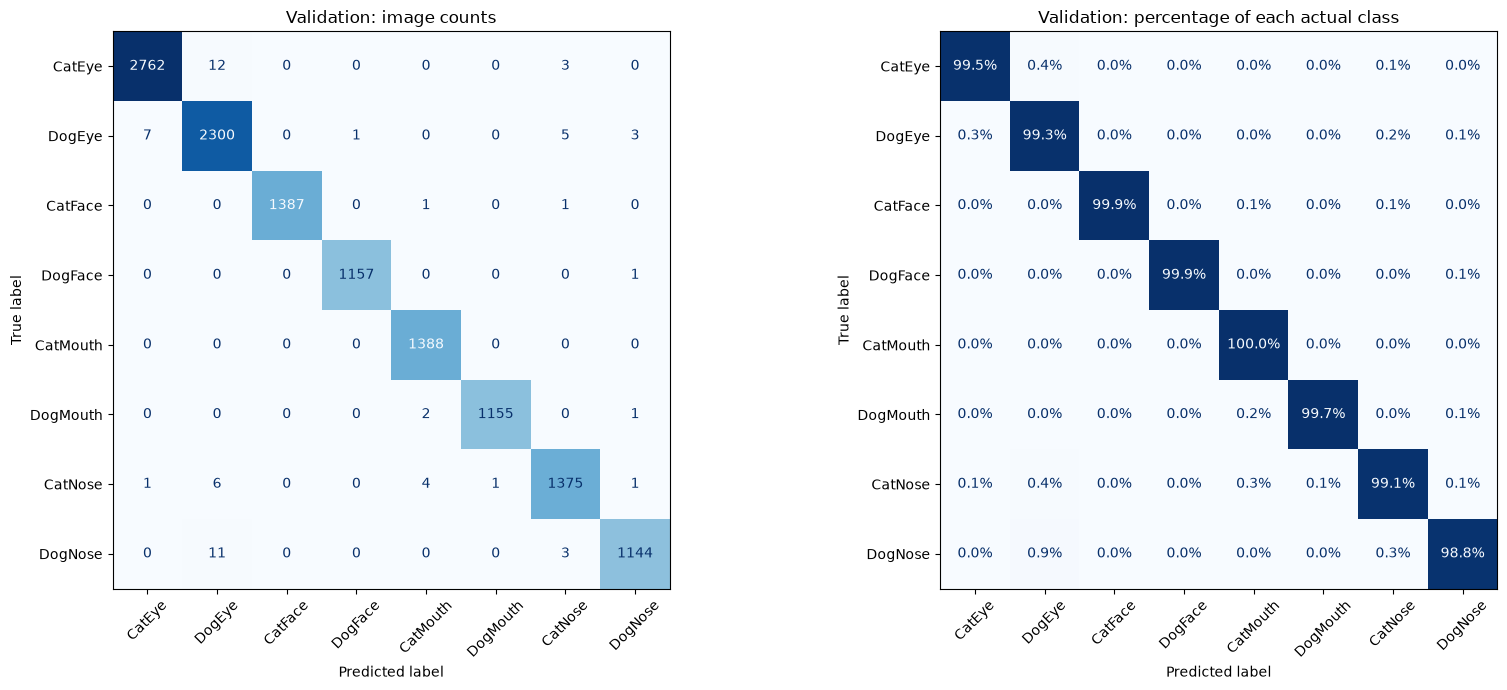

,actual_class,predicted_class,count
0,CatEye,DogEye,12
16,DogNose,DogEye,11
2,DogEye,CatEye,7
12,CatNose,DogEye,6
4,DogEye,CatNose,5
13,CatNose,CatMouth,4
1,CatEye,CatNose,3
17,DogNose,CatNose,3
5,DogEye,DogNose,3
9,DogMouth,CatMouth,2


In [6]:
# CHUNK T5 4
# this chunks displays confusion matrices rows actual classes, cols predicted.
# expected, values concentrated along main diagonal with ideally mostly 0's everywhere else. 
# dispayc ount and row normalised confusion matrixes
# show which classes the model confuses: my guess dogs
# a single accurracy value doesnt explain remaining errors; this might
# compare true and predicted labels using saved class order. 

class_indices_t5 = list(range(len(class_names_t5)))

cm_counts_t5 = confusion_matrix(
    true_labels_t5,
    predicted_labels_t5,
    labels=class_indices_t5
)

cm_normalised_t5 = confusion_matrix(
    true_labels_t5,
    predicted_labels_t5,
    labels=class_indices_t5,
    normalize="true"
)

fig_t5, axes_t5 = plt.subplots(1, 2, figsize=(17, 7))

for ax, matrix, title, number_format in [
    (axes_t5[0], cm_counts_t5, "Validation: image counts", "d"),
    (
        axes_t5[1], cm_normalised_t5,
        "Validation: percentage of each actual class", ".1%"
    )
]:
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=class_names_t5
    ).plot(
        ax=ax,
        cmap="Blues",
        values_format=number_format,
        colorbar=False,
        xticks_rotation=45
    )
    ax.set_title(title)

fig_t5.tight_layout()
fig_t5.savefig(
    TASK5_DIR / "validation_confusion_matrices.png",
    dpi=150
)
plt.show()

pd.DataFrame(
    cm_counts_t5,
    index=class_names_t5,
    columns=class_names_t5
).rename_axis("actual_class").to_csv(
    TASK5_DIR / "confusion_matrix_counts.csv"
)

# List the most frequent off-diagonal errors.
confusion_pairs_t5 = pd.DataFrame([
    {
        "actual_class": class_names_t5[i],
        "predicted_class": class_names_t5[j],
        "count": int(cm_counts_t5[i, j])
    }
    for i in class_indices_t5
    for j in class_indices_t5
    if i != j and cm_counts_t5[i, j] > 0
], columns=["actual_class", "predicted_class", "count"])

confusion_pairs_t5 = confusion_pairs_t5.sort_values(
    "count", ascending=False
)

display(confusion_pairs_t5.head(10))

confusion_pairs_t5.to_csv(
    TASK5_DIR / "confusion_pairs.csv",
    index=False
)

CNN's are actually insane. 

interpretation

diagonal entries = good, correct class representation. off diagonal entries show the actual class and incorrect class predicted by the model 

the count matrix shows the absolute number of mistakes, the row normalised matric expresses predictions as proportions of each actual class allowing comparison despite unequal class size. 

each disgonal entry in the row normalised matrix corresponds to that classes recall. 

i wonder if its possible to pull up some validation images, there's not much to be honest, could visually go through it later or in task 6.

In [ ]:
# CHUNK T5 5
# obtain the kaggle test predictions. 
# code either reuses it from task 3? or generates it. 
# reuses completed file or regenerates it
# read the saved csv otherwise re;run the model i guess. 

template_t5 = pd.read_csv(
    DATA_DIR / "sample_submission.csv",
    dtype="string"
)

SUBMISSION_PATH_T5 = T5_RUN_DIR / "submission_resnet18.csv"

if SUBMISSION_PATH_T5.is_file():
    submission_t5 = pd.read_csv(
        SUBMISSION_PATH_T5,
        dtype="string"
    )
    print("Loaded the existing Task 3 submission.")

else:
    test_dataset_t5 = FacialFeatureDataset(
        test_manifest,
        eval_transform,
        is_test=True
    )

    test_loader_t5 = DataLoader(
        test_dataset_t5,
        batch_size=int(config_t5["batch_size"]),
        shuffle=False,
        num_workers=0,
        pin_memory=DEVICE_T5.type == "cuda",
        drop_last=False
    )

    test_ids_t5 = []
    test_classes_t5 = []

    with torch.inference_mode():
        for batch_number, (images, image_ids) in enumerate(
            test_loader_t5, start=1
        ):
            images = images.to(DEVICE_T5)
            indices = model_t5(images).argmax(dim=1).cpu().tolist()

            test_ids_t5.extend(str(image_id) for image_id in image_ids)
            test_classes_t5.extend(
                index_to_class_t5[index] for index in indices
            )

            if batch_number % 100 == 0 or batch_number == len(
                test_loader_t5
            ):
                print(
                    f"Test prediction: batch {batch_number}/"
                    f"{len(test_loader_t5)}",
                    flush=True
                )

    test_predictions_t5 = pd.DataFrame({
        "image_id": test_ids_t5,
        "class": test_classes_t5
    })

    assert test_predictions_t5["image_id"].is_unique
    assert set(test_predictions_t5["image_id"]) == set(
        template_t5["image_id"]
    )

    # Restore the template's exact ID order.
    submission_t5 = template_t5[["image_id"]].merge(
        test_predictions_t5,
        on="image_id",
        how="left",
        sort=False,
        validate="one_to_one"
    )

    print("Test predictions regenerated.")
    # YESSSSS ISAVED IT

Loaded the existing Task 3 submission.


kaggle test prediction

task 3 i checked, generated predictions for all 29,443 supplied test images using the selected checkpoint. task 5 reuses that file with a regen path if it was missing. 

test images use the same deterministic preprocessing as validation. each prediction is the class associated with the largest model logit. 

the sample sub supplies the required image IDs and column structure. 

In [8]:
# CHUNK T5 6
# validate the submission and record 
# check IDs, labels, cols and row order before  my upload
# correctly trained model needs correctly cformatted CSV
# compare with the template and record the exact file characteristics. 

assert list(template_t5.columns) == ["image_id", "class"]
assert list(submission_t5.columns) == ["image_id", "class"]

assert template_t5["image_id"].notna().all()
assert template_t5["image_id"].is_unique
assert submission_t5.notna().all().all()
assert submission_t5["image_id"].is_unique

assert len(submission_t5) == len(template_t5)
assert submission_t5["image_id"].astype(str).tolist() == (
    template_t5["image_id"].astype(str).tolist()
)
assert submission_t5["class"].isin(class_names_t5).all()

# A regenerated file is written only after passing the checks.
if not SUBMISSION_PATH_T5.is_file():
    submission_t5.to_csv(SUBMISSION_PATH_T5, index=False)

saved_t5 = pd.read_csv(SUBMISSION_PATH_T5, dtype="string")
assert saved_t5.astype(str).equals(submission_t5.astype(str))

submission_hash_t5 = hashlib.sha256(
    SUBMISSION_PATH_T5.read_bytes()
).hexdigest()

artifact_t5 = {
    "run": COMPLETED_RUN_T5,
    "checkpoint": str(CHECKPOINT_PATH_T5),
    "selected_stage": checkpoint_t5["stage"],
    "selected_stage_epoch": int(checkpoint_t5["epoch"]),
    "submission_file": str(SUBMISSION_PATH_T5),
    "submission_rows": len(saved_t5),
    "submission_sha256": submission_hash_t5,
    "validation_metrics": metrics_t5
}

with (TASK5_DIR / "submission_details.json").open(
    "w", encoding="utf-8"
) as file:
    json.dump(artifact_t5, file, indent=2)

display(saved_t5.head())
print("Submission checks passed.")
print("Shape:", saved_t5.shape)
print("UPLOAD THIS FILE:")
print(SUBMISSION_PATH_T5)

print("\nSuggested Kaggle submission description:")
print(
    f"{COMPLETED_RUN_T5} | selected fine-tuning epoch "
    f"{checkpoint_t5['epoch']} | "
    f"validation accuracy {metrics_t5['accuracy']:.6f}"
)

,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogNose
3,4,DogFace
4,5,CatMouth


Submission checks passed.
Shape: (29443, 2)
UPLOAD THIS FILE:
C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition\pipeline_metadata\training_runs\resnet18_20261019_174113_729917\submission_resnet18.csv

Suggested Kaggle submission description:
resnet18_20261019_174113_729917 | selected fine-tuning epoch 7 | validation accuracy 0.994973


damn submission score of 0.93, i want higher. 

In [12]:
# CHUNK T5 7
# this chunk records my kaggle stuff
# CHUNK T5.7 — Record the actual Kaggle result.


KAGGLE_USERNAME = "Christopher Prasad"
KAGGLE_METRIC = "Accuracy"          # Confirm first: "accuracy", "macro_f1", etc.
KAGGLE_PUBLIC_SCORE = 0.9368  # Enter a decimal score, such as 0.xxxxx.
KAGGLE_SUBMISSION_ID = "Couldn't find it"
KAGGLE_EVIDENCE_FILE = "Screenshot 2026-10-20 122738.png"

matching_metrics_t5 = {
    "accuracy": metrics_t5["accuracy"],
    "macro_f1": metrics_t5["macro_f1"],
    "weighted_f1": metrics_t5["weighted_f1"]
}

if KAGGLE_PUBLIC_SCORE is None:
    print("Pending: submit the CSV, then enter the actual Kaggle result.")

elif not KAGGLE_USERNAME.strip() or not KAGGLE_METRIC.strip():
    print("Enter your Kaggle username and the confirmed scoring metric.")

else:
    metric_key_t5 = KAGGLE_METRIC.strip().lower()
    public_score_t5 = float(KAGGLE_PUBLIC_SCORE)

    leaderboard_record_t5 = {
        **artifact_t5,
        "kaggle_username": KAGGLE_USERNAME,
        "kaggle_metric": KAGGLE_METRIC,
        "kaggle_public_score": public_score_t5,
        "kaggle_submission_id": KAGGLE_SUBMISSION_ID,
        "evidence_file": KAGGLE_EVIDENCE_FILE
    }

    if metric_key_t5 in matching_metrics_t5:
        assert 0 <= public_score_t5 <= 1, (
            "These metrics use a 0–1 scale. Check the score's units."
        )

        local_score_t5 = matching_metrics_t5[metric_key_t5]
        gap_t5 = local_score_t5 - public_score_t5

        comparison_t5 = pd.DataFrame({
            "evaluation": ["Validation", "Kaggle public"],
            "metric": [metric_key_t5, metric_key_t5],
            "score": [local_score_t5, public_score_t5]
        })

        display(comparison_t5)

        print(f"Gap (validation minus Kaggle): {gap_t5:+.6f}")

        if metric_key_t5 == "accuracy":
            print(f"Accuracy gap: {100 * gap_t5:+.3f} percentage points")

        leaderboard_record_t5["matching_validation_score"] = local_score_t5
        leaderboard_record_t5["validation_minus_kaggle"] = gap_t5

        comparison_t5.to_csv(
            TASK5_DIR / "validation_kaggle_comparison.csv",
            index=False
        )

    else:
        print(
            "Kaggle result recorded. A numerical comparison needs a "
            "validation calculation matching this metric's definition."
        )

    with (TASK5_DIR / "kaggle_result.json").open(
        "w", encoding="utf-8"
    ) as file:
        json.dump(leaderboard_record_t5, file, indent=2)

,evaluation,metric,score
0,Validation,accuracy,0.994973
1,Kaggle public,accuracy,0.936800


Gap (validation minus Kaggle): +0.058173
Accuracy gap: +5.817 percentage points


kaggle sub and comparison

kaggler username: Christopher Prasad

Scoring metric: Accuracy

Public leaderboard score: 0.9368

Evidence file name: Screenshot 2026-10-20 122738.png

Okay so i cant find what metric kaggle is using so I'm not sure how to say where my model fell behind, i didnt do alot of preprocess or augmentation; mostly just minimized data leakage. I think im going to make a psuedo-task solely dedicated to playing around with the models parameters. 

a lower kaggle score possibly reflects differences in image difficulty, class distribution, source image relations, optimism model side on the validation set. the difference alone doesnt tell me which. 

a similar score would support consistency across the two evaluated partitions. 

the validation set was used for checkpoint selection, so it was not an untouched final test set. the kaggle public score may also cover only a subset of the supplied test image; idk how the competition is grading it. 

# New pipeline and model improvement. Should technically be in task 3 but for the sake of a linear program. 

The following sections E for Experiment. I will be running a new model. I will also be reviewing images. This section exists in isolation so it can be run from fresh start up. Alot of Ai was used here, I don't know syntax but I know what I want to do. 

In [13]:
# E1
# this chunk will restore the data needed for image review and the new experiement
# it will do this by loading the existing splits, clas smappings and baseline results
# this preserves the baseline and compares experiements on the same validaiton IDs
# reads saved meta data and references the existing cleaned image copies. 

import copy
import hashlib
import json
import math
import random
import re
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from IPython.display import display

import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.transforms import v2, InterpolationMode
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

PROJECT = Path(
    r"C:\Users\chris\OneDrive - AUT University\Documents\dataeng_ai_foundation\KaggleCompetition"
)
META = PROJECT / "pipeline_metadata"
CLEAN = PROJECT / "cleaned_data"
DATA = (
    PROJECT
    / "enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch"
)

BASE_NAME = "resnet18_20261019_174113_729917"
BASE_LOG = META / "training_runs" / BASE_NAME
BASE_WEIGHTS = (
    PROJECT / "model_checkpoints" / BASE_NAME / "fine_tune_best.pt"
)

REVIEW = META / "task5_image_review"
REVIEW.mkdir(exist_ok=True)


def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))


MAPPING = read_json(META / "class_to_idx.json")
NAMES = [
    name for name, index in
    sorted(MAPPING.items(), key=lambda pair: pair[1])
]
BASE_CONFIG = read_json(BASE_LOG / "training_config.json")
BASE_METRICS = read_json(BASE_LOG / "run_summary.json")["validation"]


def read_manifest(name):
    table = pd.read_csv(
        META / f"{name}_manifest.csv",
        dtype="string"
    )
    table["clean_path"] = table["clean_path"].map(
        lambda path: str(CLEAN / path)
    )

    if "label" in table:
        table["label"] = table["label"].astype("int64")
        assert table["class"].map(MAPPING).tolist() == (
            table["label"].tolist()
        )

    assert table["image_id"].is_unique
    return table


review_train = read_manifest("train")
review_val = read_manifest("validation")
review_test = read_manifest("test")

assert set(review_train["image_id"]).isdisjoint(review_val["image_id"])
assert set(review_train["group_id"]).isdisjoint(review_val["group_id"])

VAL_IDS = review_val["image_id"].tolist()

print(
    "Saved split:",
    len(review_train), "training;",
    len(review_val), "validation"
)

Saved split: 50928 training; 12732 validation


Baseline validation mistakes: 64


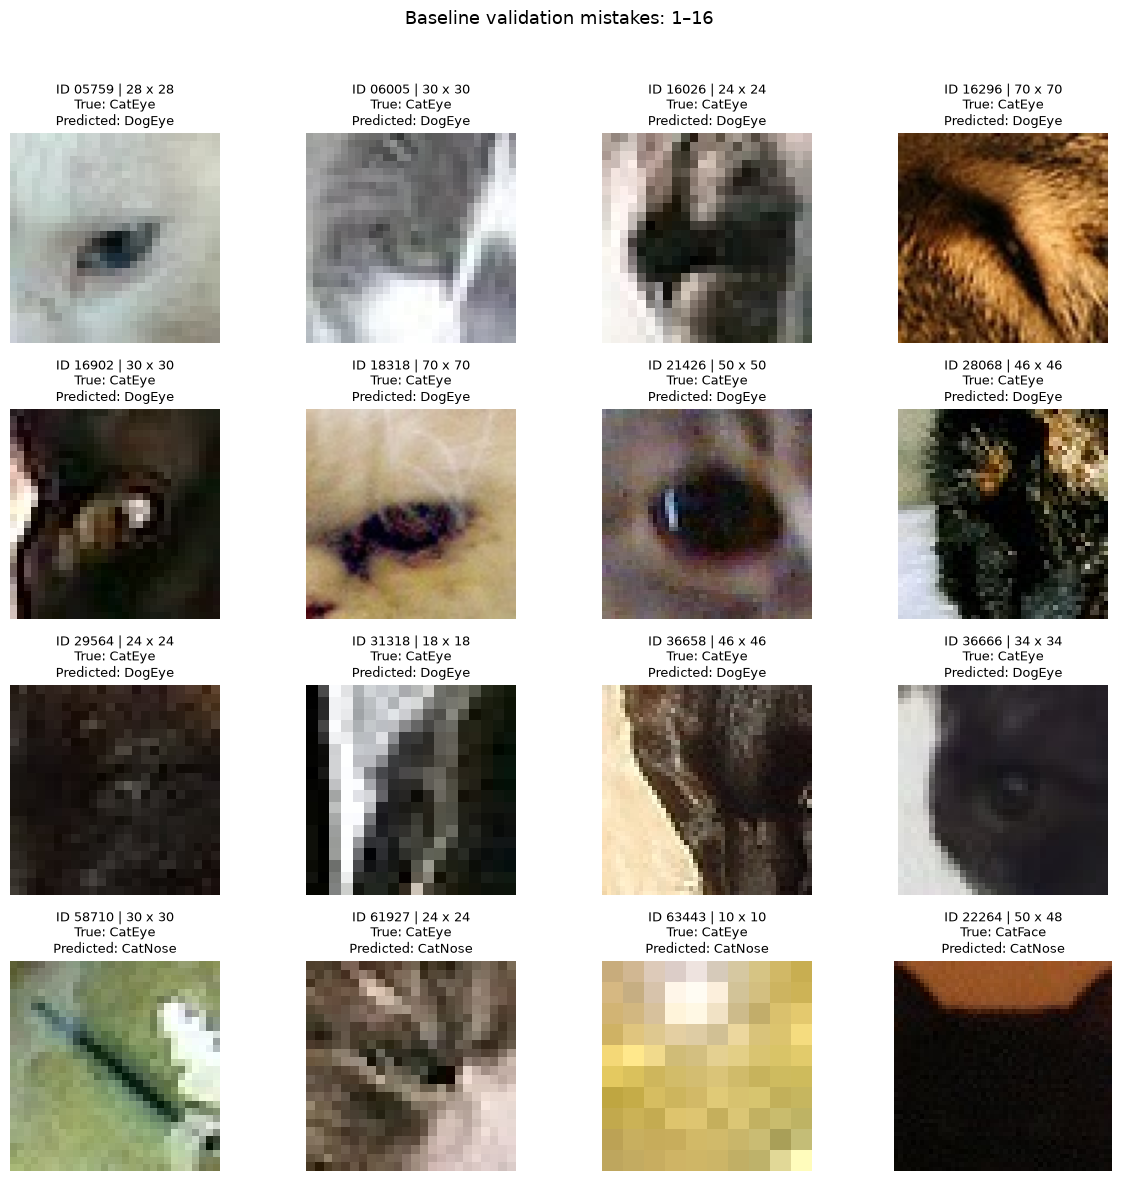

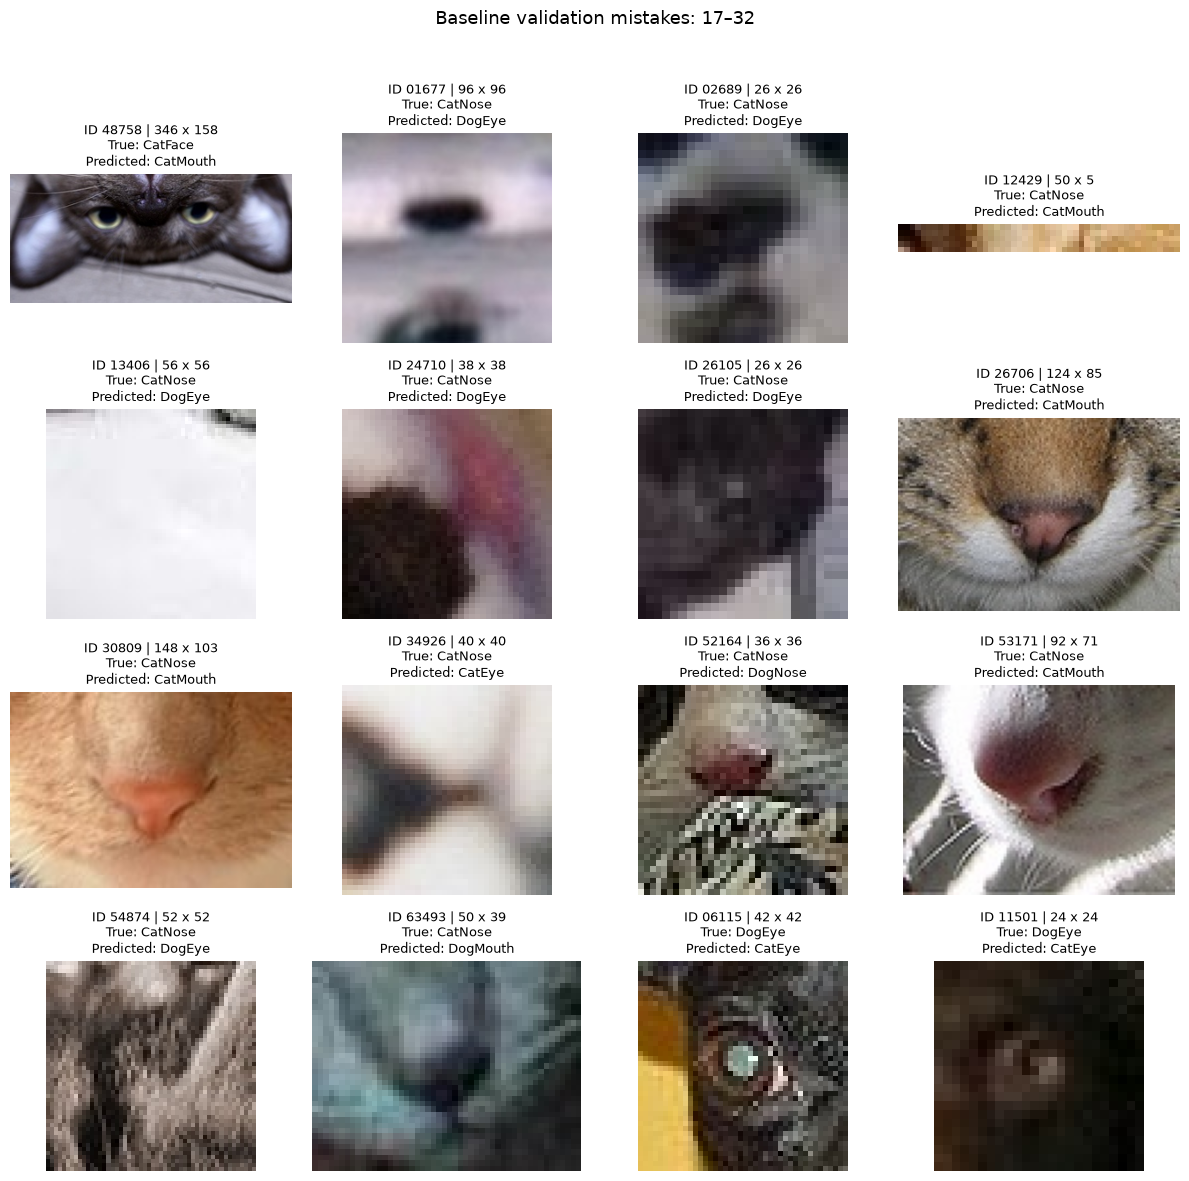

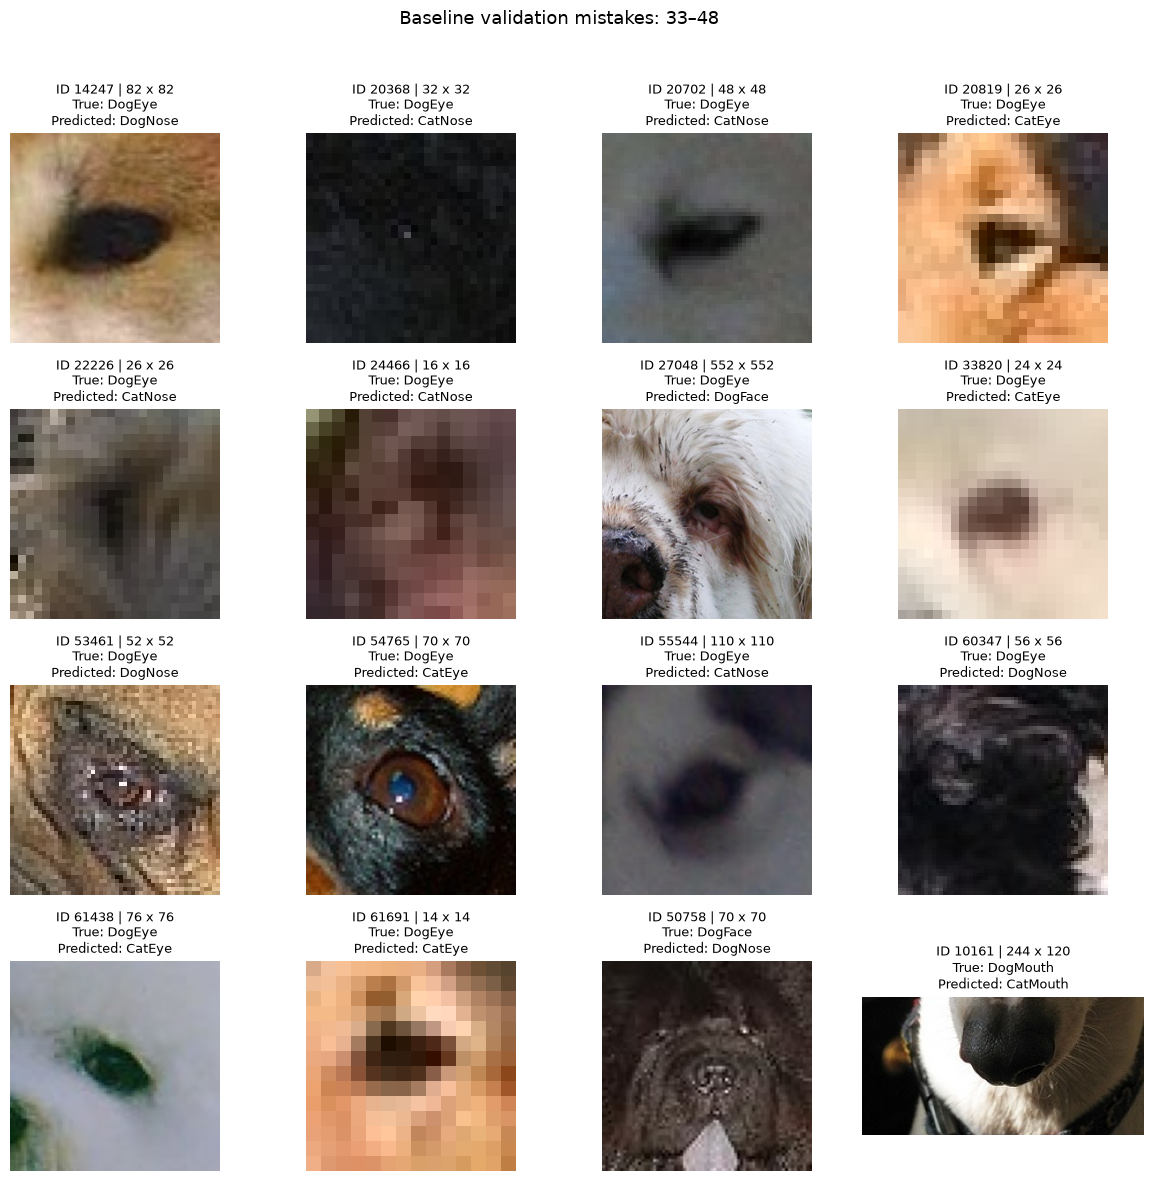

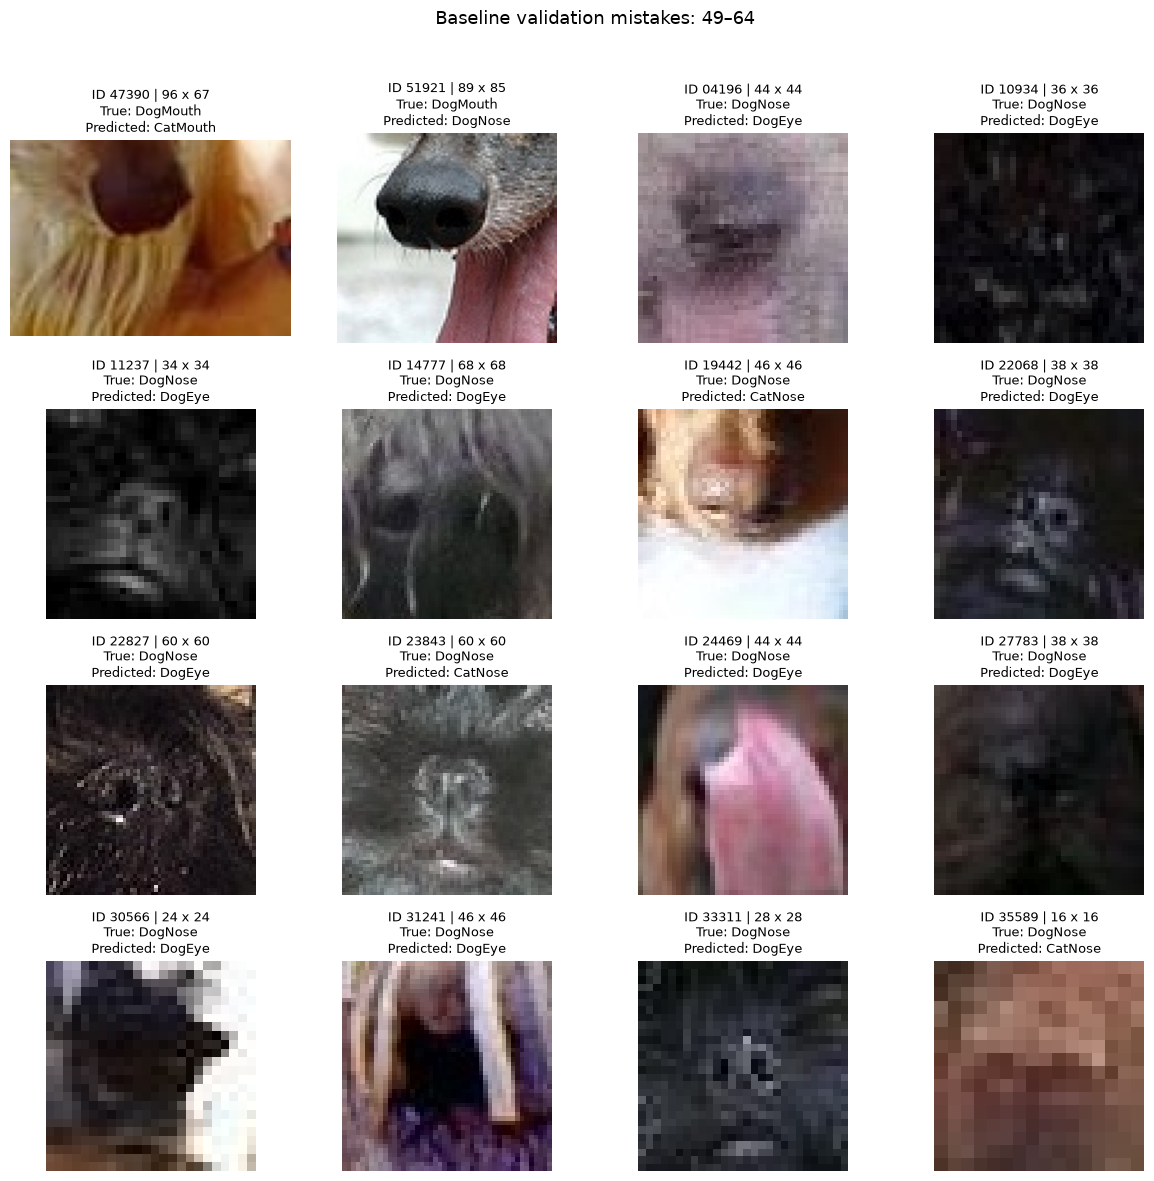

In [14]:
# E2 shows where my baseline validation made mistakes. 
# shows the actual images associated with the incorrect predictions, this was around 64 images, enough for me to check myself. 
# determine whether errors involve ambiguity, shit quality or model was not good enough. ResNet18 I will stick with, 34 doesn't gurantee better performance, 18 is very capable 
# joins saved predictions to the validation manifest and plot paginated grids. 

def show_gallery(table, title, per_page=16):
    if table.empty:
        print("No images to display.")
        return

    for start in range(0, len(table), per_page):
        page = table.iloc[start:start + per_page]
        rows = math.ceil(len(page) / 4)

        fig, axes = plt.subplots(
            rows, 4,
            figsize=(12, 3 * rows),
            squeeze=False
        )

        for ax, row in zip(axes.flat, page.to_dict("records")):
            with Image.open(row["clean_path"]) as image:
                picture = ImageOps.exif_transpose(image).convert("RGB")
                width, height = picture.size
                picture.thumbnail((320, 320))
                ax.imshow(picture)

            actual = row.get("true_class", row.get("class", ""))
            text = (
                f"ID {row['image_id']} | {width} x {height}"
                f"\nTrue: {actual}"
            )

            if "predicted_class" in row:
                text += f"\nPredicted: {row['predicted_class']}"

            ax.set_title(text, fontsize=9)

        for ax in axes.flat:
            ax.axis("off")

        fig.suptitle(
            f"{title}: {start + 1}–{start + len(page)}",
            fontsize=13
        )
        fig.tight_layout(rect=(0, 0, 1, .96))
        plt.show()
        plt.close(fig)


baseline_predictions = pd.read_csv(
    BASE_LOG / "task5_evaluation" / "validation_predictions.csv",
    dtype="string"
)

assert baseline_predictions["image_id"].is_unique
assert set(baseline_predictions["image_id"]) == set(VAL_IDS)

assert (
    baseline_predictions.set_index("image_id")["true_class"]
    .reindex(VAL_IDS).tolist()
    == review_val["class"].tolist()
)

errors = review_val.rename(columns={"class": "true_class"}).merge(
    baseline_predictions[["image_id", "predicted_class"]],
    on="image_id",
    validate="one_to_one"
)

errors = errors[
    errors["true_class"] != errors["predicted_class"]
].copy()

errors = errors.sort_values(
    ["true_class", "image_id"]
).reset_index(drop=True)

errors.to_csv(
    REVIEW / "baseline_validation_errors.csv",
    index=False
)

print("Baseline validation mistakes:", len(errors))
show_gallery(errors, "Baseline validation mistakes")

Training quality scan: 2,000/50,928
Training quality scan: 4,000/50,928
Training quality scan: 6,000/50,928
Training quality scan: 8,000/50,928
Training quality scan: 10,000/50,928
Training quality scan: 12,000/50,928
Training quality scan: 14,000/50,928
Training quality scan: 16,000/50,928
Training quality scan: 18,000/50,928
Training quality scan: 20,000/50,928
Training quality scan: 22,000/50,928
Training quality scan: 24,000/50,928
Training quality scan: 26,000/50,928
Training quality scan: 28,000/50,928
Training quality scan: 30,000/50,928
Training quality scan: 32,000/50,928
Training quality scan: 34,000/50,928
Training quality scan: 36,000/50,928
Training quality scan: 38,000/50,928
Training quality scan: 40,000/50,928
Training quality scan: 42,000/50,928
Training quality scan: 44,000/50,928
Training quality scan: 46,000/50,928
Training quality scan: 48,000/50,928
Training quality scan: 50,000/50,928


,image_id,class,width,height,sharpness
11775,14669,DogEye,30,30,0.000005
9734,12118,CatNose,16,16,0.000009
35800,44794,CatMouth,26,18,0.000011
27495,34351,DogEye,22,22,0.000012
30338,37907,CatEye,16,16,0.000013
25711,32164,CatEye,16,16,0.000016
49802,62253,CatNose,10,10,0.000016
41320,51707,CatMouth,16,12,0.000022
9976,12425,DogNose,28,28,0.000025
68,00074,DogNose,28,28,0.000029


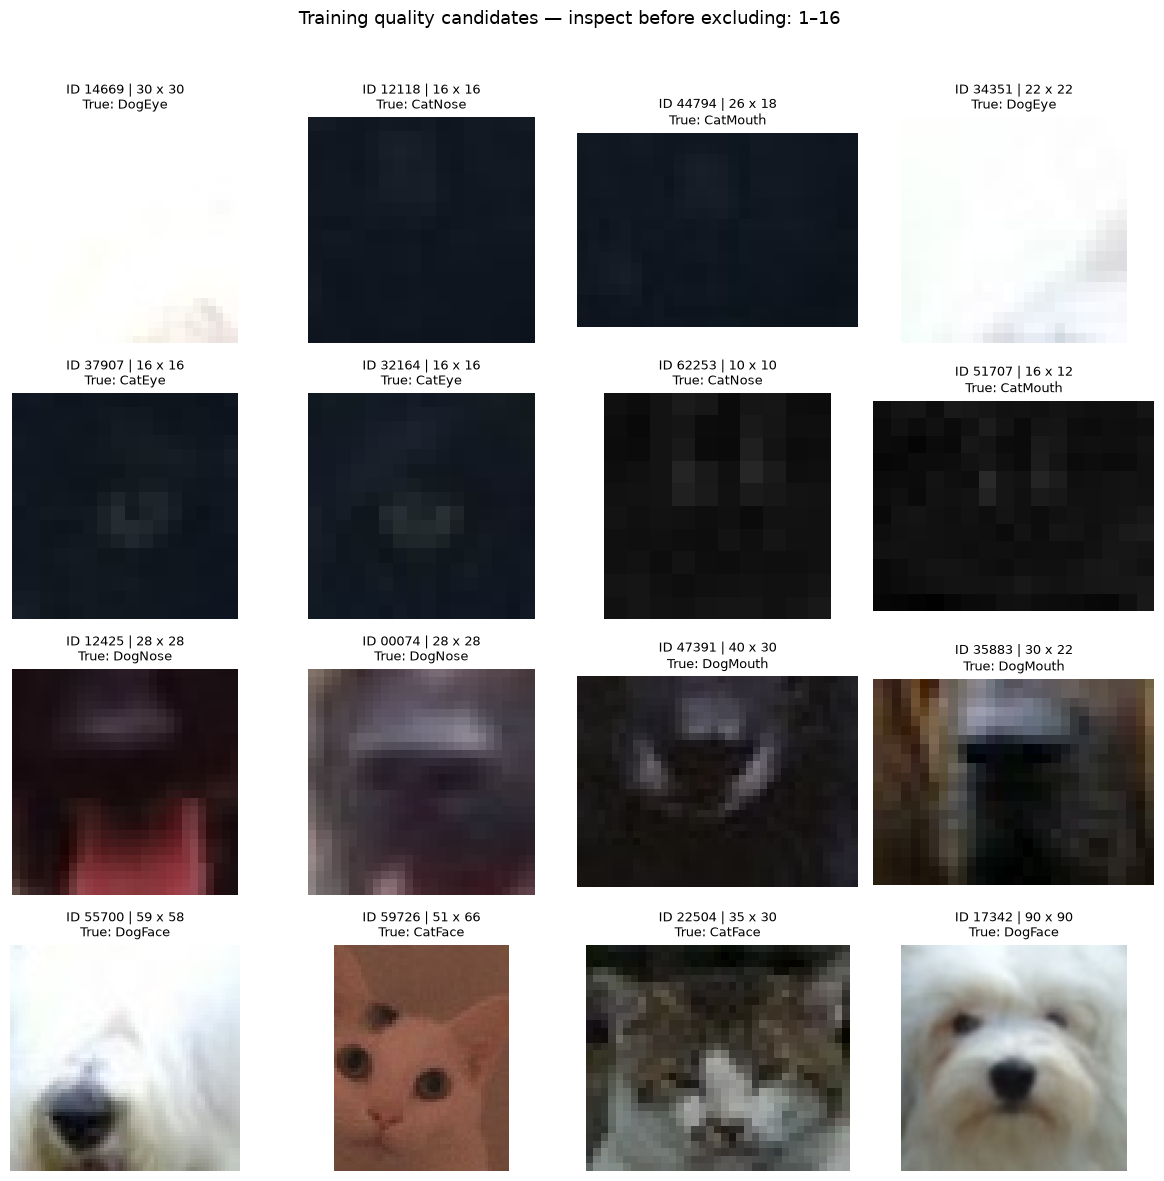

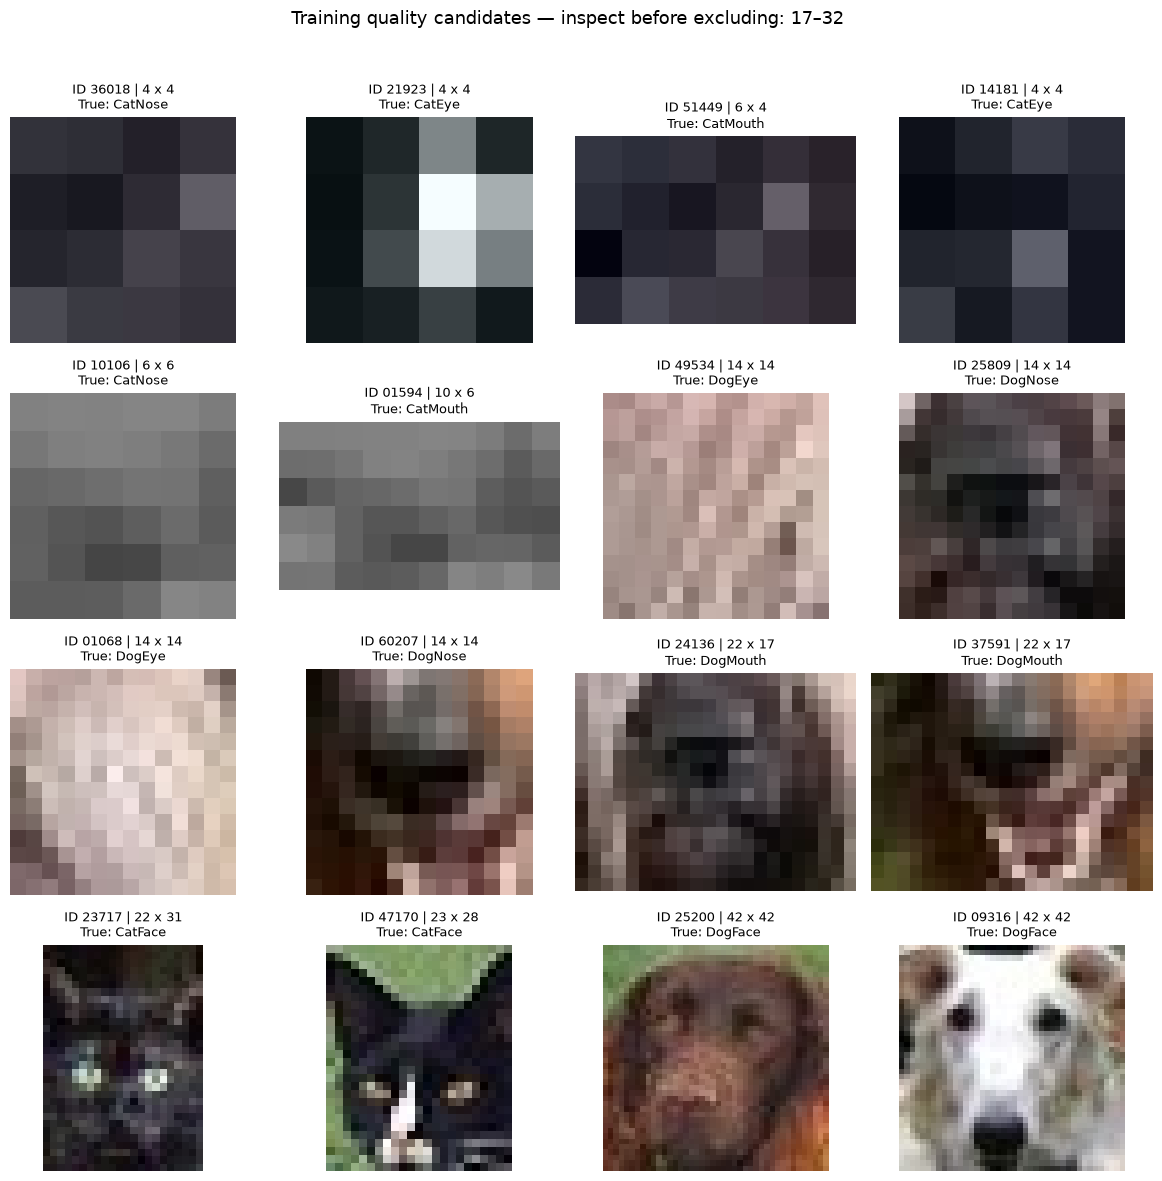

In [15]:
# the results from the validaiton set almost all of them is due to:
# poor quality
# dog nose sometimes has dog face; i noted this in my original pipeline as well. the features are not always independant of eachother. 
# E3 screens the training images for quality problems. 
# measures image dimensions and a simple sharpness score. 
# it finds training examples worth inspecting and removing. 
# ranks the candidates within each class. 

def inspect_training_image(row):
    with Image.open(row["clean_path"]) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        width, height = image.size

        gray = np.asarray(
            image.convert("L").resize((128, 128)),
            dtype=np.float32
        ) / 255

    laplacian = (
        -4 * gray[1:-1, 1:-1]
        + gray[:-2, 1:-1]
        + gray[2:, 1:-1]
        + gray[1:-1, :-2]
        + gray[1:-1, 2:]
    )

    return {
        "image_id": row["image_id"],
        "width": width,
        "height": height,
        "min_side": min(width, height),
        "sharpness": float(laplacian.var())
    }


quality_file = REVIEW / "training_quality.csv"

if quality_file.exists():
    training_quality = pd.read_csv(
        quality_file,
        dtype={"image_id": "string"}
    )
    assert training_quality["image_id"].is_unique
    assert set(training_quality["image_id"]) == set(
        review_train["image_id"]
    )

else:
    records = []

    for number, row in enumerate(
        review_train.to_dict("records"), 1
    ):
        records.append(inspect_training_image(row))

        if number % 2000 == 0:
            print(
                f"Training quality scan: "
                f"{number:,}/{len(review_train):,}",
                flush=True
            )

    training_quality = pd.DataFrame(records)
    training_quality.to_csv(quality_file, index=False)

quality_view = review_train.merge(
    training_quality,
    on="image_id",
    validate="one_to_one"
)

candidates = pd.concat([
    quality_view.sort_values("sharpness")
    .groupby("class", sort=False).head(2),

    quality_view.sort_values("min_side")
    .groupby("class", sort=False).head(2)
]).drop_duplicates("image_id")

display(candidates[
    ["image_id", "class", "width", "height", "sharpness"]
])

show_gallery(
    candidates,
    "Training quality candidates — inspect before excluding"
)

In [17]:
# E4 — Record manual training-image decisions.
# WHAT: Select training exclusions and the scope of training augmentation.
# WHY: Make cleaning decisions explicit, reversible, and reproducible.
# HOW: Filter a copied manifest and retain a reason for every exclusion.
# E4
# this chunk of code gives me manual control to exclude or augment the images. 
# each decision is justified. 

EXCLUDE_TRAIN = {
    "14669": "Clump of pixels, no valuable learning extracted from this. These types of images are the only ones I will exclude; this reason applies to all below.",
    "12118": ".",
    "44794": ".",
    "34357": ".",
    "37907": ".",
    "32164": ".",
    "62253": ".",
    "57707": ".",
    "36018": ".",
    "21923": ".",
    "51449": ".",
    "14181": ".",
    "10106": ".",
    "01594": ".",
    "49534": ".",
    "25809": ".",
    "01068": "."
}
# why didnt i remove 60207 and 35951. Because even though it's confusing to me, it holds valuable data and discernable information, not all images in the test set or validation set are perfect, so it learns something 
# and it might also make it more robust. the most powerful CNN is in my head, and that ones telling me the pictures I picked out are useless. May be worth augmenting them however. But augmenting all maximises the CNN, i will do that

AUGMENT_ONLY_TRAIN_IDS = None
# None             -> augment all retained training images
# []               -> augment none
# ["01234", ...]   -> augment 


def apply_training_decisions(train, validation, excluded, selected):
    training_ids = set(train["image_id"])
    requested = set(excluded)

    assert requested <= training_ids, (
        "Exclusions must be training IDs with their original leading zeros. "
        f"Unknown/validation IDs: {sorted(requested - training_ids)}"
    )

    assert all(
        isinstance(reason, str) and reason.strip()
        for reason in excluded.values()
    )

    if selected is not None:
        assert set(selected) <= training_ids - requested, (
            "Augmentation selection must contain retained training IDs only."
        )

    retained = train[
        ~train["image_id"].isin(requested)
    ].copy().reset_index(drop=True)

    assert set(retained["class"]) == set(train["class"]), (
        "Do not remove an entire class."
    )
    assert set(retained["image_id"]).isdisjoint(validation["image_id"])

    excluded_rows = train[
        train["image_id"].isin(requested)
    ][["image_id", "class"]].copy()

    excluded_rows["reason"] = excluded_rows["image_id"].map(excluded)

    return retained, excluded_rows


fit_train, exclusion_log = apply_training_decisions(
    review_train,
    review_val,
    EXCLUDE_TRAIN,
    AUGMENT_ONLY_TRAIN_IDS
)

print("Retained training images:", len(fit_train))
print("Excluded training images:", len(exclusion_log))
print("Validation images retained:", len(review_val))
display(exclusion_log)

Retained training images: 50911
Excluded training images: 17
Validation images retained: 12732


,image_id,class,reason
858,01068,DogEye,.
1263,01594,CatMouth,.
8116,10106,CatNose,.
9734,12118,CatNose,.
11391,14181,CatEye,.
11775,14669,DogEye,"Clump of pixels, no valuable learning extracte..."
17586,21923,CatEye,.
20655,25809,DogNose,.
25711,32164,CatEye,.
27500,34357,DogMouth,.


In [19]:
# E5 is an control panel of ResNet18. 
# it gives me full control over the models configuration and hyperparameters. 

CONTROL = {
    # 01 Run label. Use a descriptive name for each comparison.
    "tag": "rn18_b24_do4_l3l4_adamw_v1",

    # 02 Architecture: resnet18, resnet34, or resnet50.
    # Compare larger models later; they require more compute and memory.
    "architecture": "resnet18",

    # 03 Initial weights:
    # "imagenet" fresh pretrained experiment.
    # "baseline" already trained ResNet-18 checkpoint.
    # Baseline initialisation requires architecture="resnet18".
    "initialization": "imagenet",

    # 04 Input size. Start 224; separately could try 256.
    # Larger inputs cost memory and do not restore missing image detail.
    "image_size": 224,

    # 05 Random seed. Keep 42 initially; later check another seed.
    "seed": 42,

    # 06 Batch size. Start 32; reduce to 16 if GPU memory is insufficient.
    "batch_size": 24,
    # larger batch sizes are faster to run however it is prone to overfitting. mild case of this was experienced in my first mode. 
    # though not a power of 2 so inefficient use of my hardware, 24 is my selected batch size. 

    # 07 Classifier dropout. Compare 0.1 / 0.3 / 0.5.
    # More dropout regularises more, but can also cause underfitting.
    "dropout": 0.4,
    # higher = more robust, but alot of data is lost
    # lower = faster but can cause overfitting
    # im gonna go with 0.4

    # 08 Backbone modules allowed to learn during fine-tuning.
    # Start ["layer4"]; separately try ["layer3", "layer4"].
    # [] means classifier only.
    # Full backbone:
    # ["conv1", "bn1", "layer1", "layer2", "layer3", "layer4"]
    "unfreeze": ["layer4", "layer3"],
    # full backbone might blow up my gpu but i have alot of images, im going to allow the model to adapt layer3 as well as layer4. however learning rate must be lowered. why? i dont want to destroy ResNet18s already 
    # learnt usefull stuff, more like a gentle nudge. 

    # 09 Classifier warm-up epochs. Usually 1–3.
    # Starting from your trained baseline? Usually set this to 0.
    "head_epochs": 3,

    # 10 Fine-tuning epoch cap. Start 12; early stopping may finish sooner.
    # BOTH epoch values can be 0 for baseline evaluation/TTA only.
    "fine_epochs": 12,

    # 11 Warm-up classifier learning rate.
    # Try 3e-4 / 1e-3; reduce if updates are unstable.
    "head_lr": 1e-3,
    # brand new resnet, random guesses, a value too high will just latch onto randomness and destroy everything. 
    # warmup allows learning essential stuff. 

    # 12 Classifier learning rate during fine-tuning.
    # Try 3e-5 / 1e-4 / 3e-4.
    "fine_head_lr": 2e-4,
    # classifier, slower rate here for ... fine tuning. using 2e-4

    # 13 Backbone learning rate during fine-tuning.
    # Try 1e-6 / 1e-5 / 3e-5.
    # Use smaller values when unfreezing more layers.
    "backbone_lr": 1e-5,
    #backbone unfrozen, keeping as is. 

    # 14 Optimiser: "adamw" or "sgd".
    # The learning-rate defaults above are intended for AdamW.
    # Switching optimiser requires a separate learning-rate experiment.
    "optimizer": "adamw",

    # 15 Momentum: used only by SGD. Usually leave at 0.9 initially.
    "momentum": 0.9,

    # 16 Weight decay. 1e-4 
    # Larger values penalise weights more strongly.
    "weight_decay": 4e-4,

    # 17 Label smoothing. Compare 0 / 0.05 / 0.1.
    # Can reduce overconfidence, but may also reduce useful confidence.
    "label_smoothing": 0.01,

    # 18 Inverse-frequency class weights.
    # Calculated from retained TRAINING labels only.
    # Compare False versus True; weighting is not automatically better.
    "class_weights": False,
    # imbalance is not extreme, false is fine

    # 19 Learning-rate schedule: "plateau", "cosine", or "none".
    # Plateau responds to validation loss; cosine follows an epoch schedule.
    "scheduler": "plateau",

    # 20 Plateau patience: allow two unsuccessful epochs,
    # then reduce after the third.
    "scheduler_patience": 2,

    # 21 Plateau multiplier. 0.5 halves learning rates.
    # Start with 0.5 before testing a more aggressive 0.1.
    "lr_factor": 0.5,

    # 22 Minimum scheduled learning rate.
    # Keep below all starting learning rates.
    "min_lr": 1e-7,

    # 23 Early-stopping patience within each stage.
    # Start 4; try 6 if reduced learning rates need more recovery time.
    "early_patience": 4,

    # 24 Gradient norm cap. 0 disables clipping.
    # Separately try 1.0 if updates become unstable.
    "clip_norm": 0.0,

    # 25 Mixed precision on CUDA.
    # True may reduce memory use and speed training.
    # False keeps this first comparison closer to the original numerics.
    "amp": False,

    # 26 Update BatchNorm statistics in unfrozen modules.
    # False freezes running statistics; affine weights can still learn.
    "update_bn_stats": True,

    # 27 Prediction-time horizontal-flip augmentation.
    # Average original/flipped LOGITS for EVERY validation/test image.
    # No training update; roughly doubles inference work.
    "flip_tta": False,

    # 28 Training horizontal-flip probability.
    # 0 disables it; 0.5 is a useful starting point.
    "flip_p": 0.5,

    # 29 Brightness variation. Start around 0.1–0.2.
    "brightness": 0.15,

    # 30 Contrast variation. Start around 0.1–0.2.
    "contrast": 0.15,

    # 31 Saturation variation. Keep mild to preserve plausible colours.
    "saturation": 0.1,

    # 32 Rotation range, in degrees. Compare 0 / 5 / 10.
    # Large angles can damage already tight crops.
    "rotation": 4.0,

    # 33 Translation fraction. 0.03 permits shifts up to 3% per axis.
    "translate": 0.03,

    # 34 Scale variation. 0.03 samples scales from 0.97 to 1.03.
    # Inspect previews for lost feature edges.
    "scale_jitter": 0.03,

    # 35 Probability of mild synthetic blur.
    # Start disabled; separately try 0.05.
    # This simulates degradation; it does not repair blurry originals.
    "blur_p": 0.01,

    # 36 Random-erasing probability.
    # Start disabled; cautiously test 0.05 later.
    # Erasing can remove the actual eye, nose, or mouth.
    "erase_p": 0.0,
}

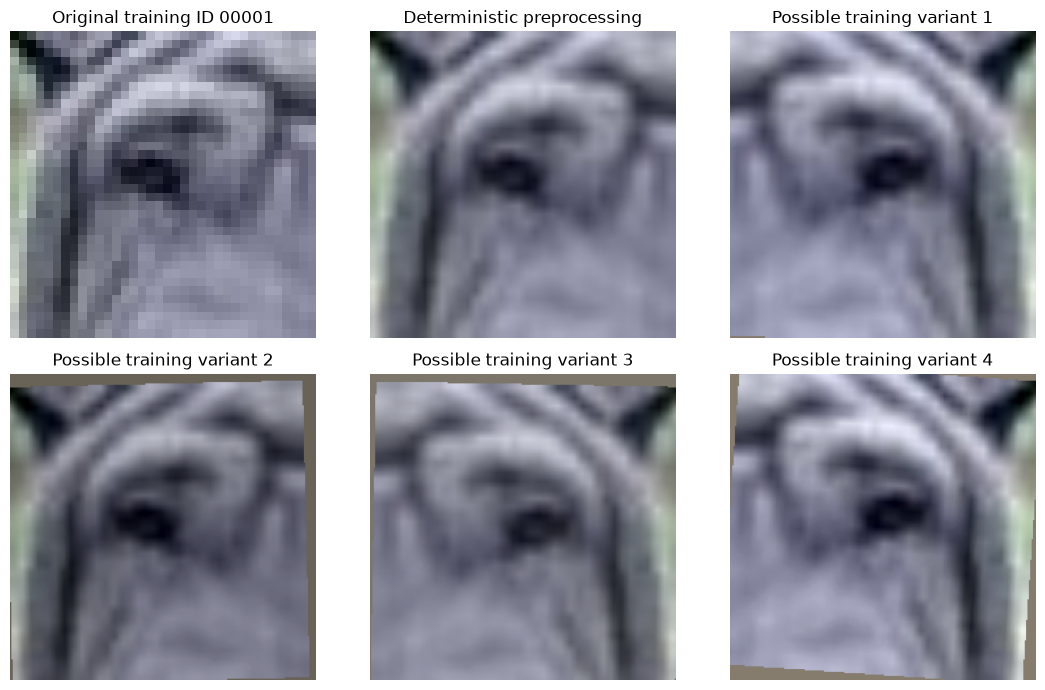

In [ ]:
# E6
# this chunk of code freezes this experiemnts settings and previews the augmentation 
# before spending a billion minutes training. 
# build training and eval transofmrs plus an experiemental dataset
# inspect label preserving changes. 
# augment eligible images. 

C = copy.deepcopy(CONTROL)

assert re.fullmatch(r"[A-Za-z0-9_-]+", C["tag"])
assert C["architecture"] in {"resnet18", "resnet34", "resnet50"}
assert C["initialization"] in {"imagenet", "baseline"}
assert C["initialization"] != "baseline" or C["architecture"] == "resnet18"
assert C["image_size"] >= 32 and C["batch_size"] >= 1
assert C["head_epochs"] >= 0 and C["fine_epochs"] >= 0
assert C["head_epochs"] + C["fine_epochs"] > 0 or (
    C["initialization"] == "baseline"
)
assert C["early_patience"] >= 1
assert C["scheduler_patience"] >= 0
assert C["optimizer"] in {"adamw", "sgd"}
assert C["scheduler"] in {"plateau", "cosine", "none"}
assert 0 < C["lr_factor"] < 1
assert 0 <= C["label_smoothing"] < 1
assert 0 <= C["dropout"] < 1
assert all(
    0 <= C[key] <= 1
    for key in ["flip_p", "blur_p", "erase_p"]
)
assert 0 <= C["translate"] <= 1
assert 0 <= C["scale_jitter"] < 1
assert all(
    C[key] > 0
    for key in ["head_lr", "fine_head_lr", "backbone_lr"]
)
assert 0 <= C["min_lr"] <= min(
    C["head_lr"], C["fine_head_lr"], C["backbone_lr"]
)
assert len(C["unfreeze"]) == len(set(C["unfreeze"]))
assert set(C["unfreeze"]) <= {
    "conv1", "bn1", "layer1", "layer2", "layer3", "layer4"
}

C["mean"], C["std"] = BASE_CONFIG["mean"], BASE_CONFIG["std"]
C["num_classes"] = len(NAMES)
C["weights"] = "IMAGENET1K_V1"
C["baseline_source"] = (
    str(BASE_WEIGHTS) if C["initialization"] == "baseline" else None
)
C["torch_version"] = str(torch.__version__)
C["torchvision_version"] = str(torchvision.__version__)

chosen_aug_ids = (
    None if AUGMENT_ONLY_TRAIN_IDS is None
    else set(AUGMENT_ONLY_TRAIN_IDS)
)

pad_colour = tuple(round(255 * value) for value in C["mean"])
size_for_run = C["image_size"]


def experiment_pad(image):
    return ImageOps.pad(
        image,
        (size_for_run, size_for_run),
        method=Image.Resampling.BILINEAR,
        color=pad_colour
    )


normalisation = [
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(mean=C["mean"], std=C["std"])
]

exp_eval_transform = v2.Compose(
    [v2.Lambda(experiment_pad)] + normalisation
)

exp_aug_transform = v2.Compose([
    v2.Lambda(experiment_pad),
    v2.RandomHorizontalFlip(p=C["flip_p"]),
    v2.RandomAffine(
        degrees=C["rotation"],
        translate=(C["translate"], C["translate"]),
        scale=(1 - C["scale_jitter"], 1 + C["scale_jitter"]),
        interpolation=InterpolationMode.BILINEAR,
        fill=pad_colour
    ),
    v2.ColorJitter(
        brightness=C["brightness"],
        contrast=C["contrast"],
        saturation=C["saturation"]
    ),
    v2.RandomApply(
        [v2.GaussianBlur(3, sigma=(0.1, 1.0))],
        p=C["blur_p"]
    ),
] + normalisation + [
    # Zero after normalisation corresponds to the normalisation mean.
    v2.RandomErasing(
        p=C["erase_p"],
        scale=(.02, .08),
        ratio=(.5, 2),
        value=0
    )
])


class ExperimentDataset(Dataset):
    def __init__(self, table, training=False, test=False):
        self.table = table.reset_index(drop=True).copy()
        self.training = training
        self.test = test

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        use_aug = self.training and (
            chosen_aug_ids is None
            or row["image_id"] in chosen_aug_ids
        )

        transform = (
            exp_aug_transform if use_aug else exp_eval_transform
        )

        with Image.open(row["clean_path"]) as image:
            tensor = transform(
                ImageOps.exif_transpose(image).convert("RGB")
            )

        target = (
            str(row["image_id"]) if self.test
            else int(row["label"])
        )
        return tensor, target


def show_tensor(ax, tensor):
    mean = torch.tensor(C["mean"]).view(3, 1, 1)
    std = torch.tensor(C["std"]).view(3, 1, 1)

    picture = (
        (tensor.cpu() * std + mean)
        .clamp(0, 1)
        .permute(1, 2, 0)
        .numpy()
    )
    ax.imshow(picture)


# Change this to a retained TRAINING image ID to inspect another example.
PREVIEW_TRAIN_ID = str(fit_train.iloc[0]["image_id"])
preview_row = fit_train.set_index("image_id").loc[PREVIEW_TRAIN_ID]

with Image.open(preview_row["clean_path"]) as image:
    source = ImageOps.exif_transpose(image).convert("RGB")

fig, axes = plt.subplots(2, 3, figsize=(11, 7))

axes[0, 0].imshow(source)
axes[0, 0].set_title(f"Original training ID {PREVIEW_TRAIN_ID}")

show_tensor(axes[0, 1], exp_eval_transform(source))
axes[0, 1].set_title("Deterministic preprocessing")

for number, ax in enumerate(list(axes.flat)[2:], 1):
    show_tensor(ax, exp_aug_transform(source))
    ax.set_title(f"Possible training variant {number}")

for ax in axes.flat:
    ax.axis("off")

fig.tight_layout()
plt.show()
plt.close(fig)

# very neat

In [21]:
# E7 
# this chunk defines re usable model and epoch functions for all possible models i want to run. 
# controls trianable modules, optimasation behaviour and eval 
# keeps experimental procedure consistent acrosss configs 
# freezes selected parameters and uses separate training/eval modes.

REGISTRY = {
    "resnet18": (
        models.resnet18,
        models.ResNet18_Weights.IMAGENET1K_V1
    ),
    "resnet34": (
        models.resnet34,
        models.ResNet34_Weights.IMAGENET1K_V1
    ),
    "resnet50": (
        models.resnet50,
        models.ResNet50_Weights.IMAGENET1K_V1
    ),
}


def experiment_network(config, pretrained=False):
    builder, weights = REGISTRY[config["architecture"]]
    network = builder(weights=weights if pretrained else None)

    network.fc = nn.Sequential(
        nn.Dropout(config["dropout"]),
        nn.Linear(network.fc.in_features, config["num_classes"])
    )
    return network


def seed_experiment(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def select_trainable(network, fine_tune):
    for parameter in network.parameters():
        parameter.requires_grad_(False)

    for parameter in network.fc.parameters():
        parameter.requires_grad_(True)

    if fine_tune:
        for part in C["unfreeze"]:
            for parameter in getattr(network, part).parameters():
                parameter.requires_grad_(True)


def evaluation_logits(images):
    logits = exp_model(images)

    if C["flip_tta"]:
        flipped_logits = exp_model(images.flip(-1))
        logits = (logits + flipped_logits) / 2

    return logits


def experiment_epoch(loader, optimizer=None, fine_tune=False):
    training = optimizer is not None
    exp_model.eval()

    if training:
        exp_model.fc.train()

        if fine_tune:
            for part in C["unfreeze"]:
                getattr(exp_model, part).train()

        if not C["update_bn_stats"]:
            for module in exp_model.modules():
                if isinstance(module, nn.BatchNorm2d):
                    module.eval()

    truth, predictions = [], []
    numerator, denominator = 0.0, 0.0
    criterion = training_loss if training else validation_loss

    with torch.set_grad_enabled(training):
        for number, (images, targets) in enumerate(loader, 1):
            images = images.to(EXP_DEVICE)
            targets = targets.to(EXP_DEVICE)

            if training:
                optimizer.zero_grad(set_to_none=True)

            with torch.autocast(
                device_type=EXP_DEVICE.type,
                enabled=AMP_ACTIVE
            ):
                logits = (
                    exp_model(images) if training
                    else evaluation_logits(images)
                )
                losses = criterion(logits, targets)

                normaliser = (
                    training_weights[targets].sum()
                    if training and training_weights is not None
                    else targets.numel()
                )
                loss = losses.sum() / normaliser

            if not torch.isfinite(loss).item():
                raise RuntimeError(
                    "Non-finite loss: inspect this configuration."
                )

            if training:
                scaler.scale(loss).backward()

                if C["clip_norm"] > 0:
                    scaler.unscale_(optimizer)
                    nn.utils.clip_grad_norm_(
                        exp_model.parameters(),
                        C["clip_norm"]
                    )

                scaler.step(optimizer)
                scaler.update()

            numerator += losses.detach().sum().item()
            denominator += float(normaliser)

            truth.extend(targets.detach().cpu().tolist())
            predictions.extend(
                logits.detach().argmax(1).cpu().tolist()
            )

            if number % 200 == 0 or number == len(loader):
                phase = "train" if training else "validation"
                print(
                    f"  {phase}: {number}/{len(loader)}",
                    flush=True
                )

    metrics = {
        "loss": numerator / denominator,
        "accuracy": float(accuracy_score(truth, predictions)),
        "macro_f1": float(f1_score(
            truth,
            predictions,
            labels=list(range(len(NAMES))),
            average="macro",
            zero_division=0
        ))
    }
    return metrics, truth, predictions

In [ ]:
# E8 preparations have been made, time to actually run the model. 
# run the configured stages and save the lowest validation loss model just like before
# compare controlled experiements while retaining their settings and evidence. 
# create unique output folders for these, monitor validaiton and save the improvements made. 

# Reset random draws consumed by the augmentation previews.
seed_experiment(C["seed"])

EXP_DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)
AMP_ACTIVE = bool(C["amp"] and EXP_DEVICE.type == "cuda")
scaler = torch.amp.GradScaler("cuda", enabled=AMP_ACTIVE)

RUN_ID = (
    C["tag"] + "_"
    + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)
EXP_LOG = META / "training_runs" / RUN_ID
EXP_WEIGHTS = PROJECT / "model_checkpoints" / RUN_ID

EXP_LOG.mkdir(parents=True, exist_ok=False)
EXP_WEIGHTS.mkdir(parents=True, exist_ok=False)


def write_json(path, value):
    path.write_text(
        json.dumps(value, indent=2),
        encoding="utf-8"
    )


write_json(EXP_LOG / "config.json", C)
write_json(EXP_LOG / "image_policy.json", {
    "exclude_training": EXCLUDE_TRAIN,
    "augment_only_training_ids": AUGMENT_ONLY_TRAIN_IDS
})

# Save the exact manifests used by this experiment.
for name, table in [
    ("train", fit_train),
    ("validation", review_val),
    ("test", review_test)
]:
    portable = table.copy()
    portable["clean_path"] = portable["clean_path"].map(
        lambda path: Path(path).relative_to(CLEAN).as_posix()
    )
    portable.to_csv(
        EXP_LOG / f"{name}_manifest.csv",
        index=False
    )

exclusion_log.to_csv(
    EXP_LOG / "training_exclusions.csv",
    index=False
)
assert review_val["image_id"].tolist() == VAL_IDS

loader_options = {
    "batch_size": C["batch_size"],
    "num_workers": 0,  # Keep 0 for this Windows notebook.
    "pin_memory": EXP_DEVICE.type == "cuda",
    "drop_last": False
}

exp_train_loader = DataLoader(
    ExperimentDataset(fit_train, training=True),
    shuffle=True,
    generator=torch.Generator().manual_seed(C["seed"]),
    **loader_options
)
exp_val_loader = DataLoader(
    ExperimentDataset(review_val),
    shuffle=False,
    generator=torch.Generator().manual_seed(C["seed"] + 1),
    **loader_options
)
exp_test_loader = DataLoader(
    ExperimentDataset(review_test, test=True),
    shuffle=False,
    generator=torch.Generator().manual_seed(C["seed"] + 2),
    **loader_options
)

exp_model = experiment_network(
    C,
    pretrained=C["initialization"] == "imagenet"
)

if C["initialization"] == "baseline":
    baseline_checkpoint = torch.load(
        BASE_WEIGHTS,
        map_location="cpu",
        weights_only=True
    )
    assert baseline_checkpoint["class_to_idx"] == MAPPING
    exp_model.load_state_dict(
        baseline_checkpoint["model_state"]
    )

exp_model = exp_model.to(EXP_DEVICE)

training_weights = None

if C["class_weights"]:
    counts = (
        fit_train["label"].value_counts()
        .reindex(range(len(NAMES)))
    )
    training_weights = torch.tensor(
        (len(fit_train) / (len(NAMES) * counts)).to_numpy(),
        dtype=torch.float32,
        device=EXP_DEVICE
    )

training_loss = nn.CrossEntropyLoss(
    weight=training_weights,
    label_smoothing=C["label_smoothing"],
    reduction="none"
)

# Always use ordinary cross-entropy for validation comparisons.
validation_loss = nn.CrossEntropyLoss(reduction="none")

BEST_EXPERIMENT = EXP_WEIGHTS / "best.pt"


def save_experiment_best(stage, epoch, stage_epoch, metrics):
    torch.save({
        "model_state": exp_model.state_dict(),
        "class_to_idx": MAPPING,
        "config": C,
        "stage": stage,
        "epoch": epoch,
        "stage_epoch": stage_epoch,
        "validation": metrics
    }, BEST_EXPERIMENT)


print("Run:", RUN_ID, "| Device:", EXP_DEVICE)

# Retain the starting model too: subsequent training must improve its loss.
initial_evaluation = experiment_epoch(exp_val_loader)
best_loss = initial_evaluation[0]["loss"]

save_experiment_best(
    "initial", 0, 0, initial_evaluation[0]
)

records = []
global_epoch = 0

for stage, epochs, fine_tune in [
    ("head", C["head_epochs"], False),
    ("fine_tune", C["fine_epochs"], True)
]:
    if epochs == 0:
        continue

    # Begin each stage from the best candidate obtained so far.
    exp_model.load_state_dict(torch.load(
        BEST_EXPERIMENT,
        map_location=EXP_DEVICE,
        weights_only=True
    )["model_state"])

    select_trainable(exp_model, fine_tune)

    groups = [{
        "params": list(exp_model.fc.parameters()),
        "lr": C["fine_head_lr"] if fine_tune else C["head_lr"]
    }]

    backbone = [
        parameter
        for name, parameter in exp_model.named_parameters()
        if parameter.requires_grad and not name.startswith("fc.")
    ]

    if backbone:
        groups.insert(0, {
            "params": backbone,
            "lr": C["backbone_lr"]
        })

    if C["optimizer"] == "adamw":
        optimizer = torch.optim.AdamW(
            groups,
            weight_decay=C["weight_decay"]
        )
    else:
        optimizer = torch.optim.SGD(
            groups,
            momentum=C["momentum"],
            weight_decay=C["weight_decay"]
        )

    if C["scheduler"] == "plateau":
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            patience=C["scheduler_patience"],
            factor=C["lr_factor"],
            min_lr=C["min_lr"],
            threshold=0,
            threshold_mode="abs"
        )
    elif C["scheduler"] == "cosine":
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
            optimizer,
            T_max=epochs,
            eta_min=C["min_lr"]
        )
    else:
        scheduler = None

    stage_best = float("inf")
    bad_epochs = 0

    for stage_epoch in range(1, epochs + 1):
        global_epoch += 1
        start_time = time.monotonic()

        print(
            f"\n{stage}: epoch {stage_epoch}/{epochs}",
            flush=True
        )

        rates = [
            group["lr"] for group in optimizer.param_groups
        ]

        train_metrics, _, _ = experiment_epoch(
            exp_train_loader, optimizer, fine_tune
        )
        val_metrics, _, _ = experiment_epoch(exp_val_loader)

        record = {
            "epoch": global_epoch,
            "stage": stage,
            "stage_epoch": stage_epoch,
            "lr_head": rates[-1],
            "lr_backbone": rates[0] if backbone else None,
            "minutes": (time.monotonic() - start_time) / 60
        }
        record.update({
            f"train_{key}": value
            for key, value in train_metrics.items()
        })
        record.update({
            f"val_{key}": value
            for key, value in val_metrics.items()
        })

        records.append(record)
        pd.DataFrame(records).to_csv(
            EXP_LOG / "history.csv",
            index=False
        )

        if val_metrics["loss"] < best_loss:
            best_loss = val_metrics["loss"]
            save_experiment_best(
                stage, global_epoch, stage_epoch, val_metrics
            )

        if val_metrics["loss"] < stage_best:
            stage_best = val_metrics["loss"]
            bad_epochs = 0
        else:
            bad_epochs += 1

        if scheduler is not None:
            if C["scheduler"] == "plateau":
                scheduler.step(val_metrics["loss"])
            else:
                scheduler.step()

        print(
            f"train {train_metrics['accuracy']:.3%} | "
            f"validation {val_metrics['accuracy']:.3%} | "
            f"validation loss {val_metrics['loss']:.6f}",
            flush=True
        )

        if bad_epochs >= C["early_patience"]:
            print("Early stopping for this stage.", flush=True)
            break

print("Experiment finished.")
print("Best checkpoint:", BEST_EXPERIMENT)
print("Results:", EXP_LOG)

In [ ]:
# E9 — Evaluate the saved winner and record the comparison.
# WHAT: Save class metrics, individual predictions, and learning curves.
# WHY: Judge the selected checkpoint using evidence rather than its final epoch.
# HOW: Reload saved weights and evaluate on the unchanged validation set.

selected = torch.load(
    BEST_EXPERIMENT,
    map_location=EXP_DEVICE,
    weights_only=True
)
exp_model.load_state_dict(selected["model_state"])
exp_model.eval()

if records:
    final_metrics, final_truth, final_predictions = experiment_epoch(
        exp_val_loader
    )
else:
    # Evaluation-only experiment: reuse the evaluation already performed.
    final_metrics, final_truth, final_predictions = initial_evaluation

write_json(
    EXP_LOG / "validation_metrics.json",
    final_metrics
)

prediction_table = review_val.rename(columns={
    "class": "true_class",
    "label": "true_label"
}).copy()

assert final_truth == prediction_table["true_label"].tolist()

prediction_table["predicted_label"] = final_predictions
prediction_table["predicted_class"] = [
    NAMES[index] for index in final_predictions
]
prediction_table.to_csv(
    EXP_LOG / "validation_predictions.csv",
    index=False
)

report = classification_report(
    final_truth,
    final_predictions,
    labels=list(range(len(NAMES))),
    target_names=NAMES,
    output_dict=True,
    zero_division=0
)

class_table = pd.DataFrame(report).T.loc[NAMES].copy()
class_table["support"] = class_table["support"].astype(int)
class_table.to_csv(
    EXP_LOG / "class_metrics.csv",
    index_label="class"
)
display(class_table.round(5))

pd.DataFrame(
    confusion_matrix(
        final_truth,
        final_predictions,
        labels=list(range(len(NAMES)))
    ),
    index=NAMES,
    columns=NAMES
).to_csv(
    EXP_LOG / "confusion_counts.csv",
    index_label="actual_class"
)

comparison = pd.DataFrame([
    {
        "run": BASE_NAME,
        "validation_accuracy": BASE_METRICS["accuracy"],
        "validation_loss": BASE_METRICS["loss"],
        "macro_f1": BASE_METRICS["macro_f1"],
        "kaggle_public_accuracy": 0.9368
    },
    {
        "run": RUN_ID,
        "validation_accuracy": final_metrics["accuracy"],
        "validation_loss": final_metrics["loss"],
        "macro_f1": final_metrics["macro_f1"],
        "kaggle_public_accuracy": None
    }
])

display(comparison)
comparison.to_csv(
    EXP_LOG / "baseline_comparison.csv",
    index=False
)

if records:
    learning = pd.DataFrame(records)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(
            learning["epoch"],
            learning[f"train_{metric}"],
            label=(
                "Training objective" if metric == "loss"
                else "Training"
            )
        )
        ax.plot(
            learning["epoch"],
            learning[f"val_{metric}"],
            label="Validation"
        )
        ax.axvline(
            selected["epoch"],
            color="black",
            linestyle=":",
            label="Selected"
        )
        ax.set(xlabel="Global epoch", ylabel=metric)
        ax.legend()

    fig.tight_layout()
    fig.savefig(EXP_LOG / "learning_curves.png", dpi=150)
    plt.show()
    plt.close(fig)

print(
    "Selected:", selected["stage"],
    "| Global epoch:", selected["epoch"]
)

# Optional: display this experiment's remaining validation mistakes.
# new_errors = prediction_table[
#     prediction_table["true_class"] != prediction_table["predicted_class"]
# ]
# show_gallery(new_errors, "New experiment validation mistakes")

In [ ]:
# E10 — Generate a separate Kaggle submission for this experiment.
# WHAT: Predict every test image using the selected candidate.
# WHY: Keep experimental submissions associated with their actual models.
# HOW: Apply the evaluation rule, restore template order, and check the CSV.

template = pd.read_csv(
    DATA / "sample_submission.csv",
    dtype="string"
)

identities, predictions = [], []
exp_model.eval()

with torch.inference_mode():
    for number, (images, image_ids) in enumerate(
        exp_test_loader, 1
    ):
        with torch.autocast(
            device_type=EXP_DEVICE.type,
            enabled=AMP_ACTIVE
        ):
            logits = evaluation_logits(images.to(EXP_DEVICE))

        indices = logits.argmax(1).cpu().tolist()
        identities.extend(str(value) for value in image_ids)
        predictions.extend(NAMES[index] for index in indices)

        if number % 200 == 0 or number == len(exp_test_loader):
            print(
                f"Test prediction: {number}/{len(exp_test_loader)}",
                flush=True
            )


def ordered_submission(template, identities, predictions, names):
    assert list(template.columns) == ["image_id", "class"]
    assert template["image_id"].notna().all()
    assert template["image_id"].is_unique
    assert len(identities) == len(predictions)

    predicted = pd.DataFrame({
        "image_id": identities,
        "class": predictions
    })

    assert predicted["image_id"].is_unique
    assert set(identities) == set(template["image_id"])

    result = template[["image_id"]].merge(
        predicted,
        on="image_id",
        how="left",
        sort=False,
        validate="one_to_one"
    )

    assert result["image_id"].tolist() == (
        template["image_id"].tolist()
    )
    assert result["class"].notna().all()
    assert result["class"].isin(names).all()

    return result


new_submission = ordered_submission(
    template, identities, predictions, NAMES
)

NEW_SUBMISSION_PATH = EXP_LOG / "submission.csv"
new_submission.to_csv(NEW_SUBMISSION_PATH, index=False)

round_trip = pd.read_csv(
    NEW_SUBMISSION_PATH,
    dtype="string"
)
assert round_trip.astype(str).equals(
    new_submission.astype(str)
)

write_json(EXP_LOG / "submission_details.json", {
    "run": RUN_ID,
    "checkpoint": str(BEST_EXPERIMENT),
    "config": C,
    "validation": final_metrics,
    "rows": len(new_submission),
    "submission_sha256": hashlib.sha256(
        NEW_SUBMISSION_PATH.read_bytes()
    ).hexdigest()
})

print("New submission:", NEW_SUBMISSION_PATH)
print("Rows:", len(new_submission))
print("Kaggle description:", RUN_ID)

# Task 6: Results Analysis and Improvement Strategies
Students must critically analyse the results and discuss possible improvements. Students are required to:

Interpret the model performance using validation results and Kaggle score.

Analyse common misclassifications and difficult classes where possible.

Discuss possible reasons for performance limitations.

Evaluate the effectiveness of preprocessing, augmentation, model choice, and training strategy.

Compare attempted model versions or experimental settings where applicable.

Propose realistic strategies for improving performance, such as alternative architectures, hyperparameter tuning, improved augmentation, fine-tuning, ensemble methods, or better validation strategies.

Reflect on the strengths and weaknesses of the final solution.


# Task 7: Report Writing and Reproducibility
Students must prepare a clear individual technical report and provide reproducible supporting files. Students are required to:

Write a structured final report of 3,000- 3,500 words, describing the complete workflow.
Include sufficient detail about the dataset, preprocessing, model, training strategy, evaluation, Kaggle results, analysis, and improvement strategies.
Provide source code or a Jupyter Notebook with clear comments and instructions.
Include the final Kaggle submission file.
Include Kaggle username and leaderboard evidence.
Reference all external libraries, models, papers, tutorials, or resources used.
Ensure that the work is original and complies with academic integrity requirements.
Submit a Turnitin similarity report with a similarity score not exceeding 20%